# Steam Games (2021-2025) Metrics Analysis

## 1. Project Background & Data Provenance
* **Dataset Source:** This dataset is retrieved from the Kaggle repository [*"Steam Games Dataset 2021-2025 (65K)"*](https://www.kaggle.com/datasets/jypenpen54534/steam-games-dataset-2021-2025-65k/data) published by user `jypenpen54534`.
* **Collection Process (`collect_data_v2.py`):**
  * Game listings were queried from Steam's official `IStoreService` API in paginated requests of 10,000 titles, filtering for `AppID > 1,200,000` to capture modern catalog releases.
  * Storefront metadata was retrieved via Steam's `appdetails` API, standardized to US pricing (USD) and English text.
  * The dataset strictly includes standalone software of type `"game"` released between January 1, 2021 and December 31, 2025.
* **Collection Snapshot Date & Exposure Limitations:**
  * The dataset contains release dates through December 31, 2025 (`max_date = '2025-12-31'`). The collection script specifies `TARGET_YEARS = range(2021, 2026)`.
  * The collection occurred following the close of the 2025 calendar year (assumed early 2026 snapshot; exact capture timestamp is unrecorded in published repository metadata).
  * Consequently, games released between 2021 and 2024 have accumulated at least ~365 days (up to 4 years) of storefront exposure at collection time, whereas games released in 2025 have had right-truncated exposure durations between 0 and 365 days.
  * We treat exposure duration as an observational limitation rather than asserting that the lower clearance rate in 2025 or December 2025 is solely attributable to truncation.
* **Terminology Note:** Throughout this analysis, "recommendations" and "reviews" refer to Steam's public store-page recommendation counter. The ~100 review threshold is inferred from the empirical minimum non-zero value ($\min = 101$).

---

## 2. Dataset Dimensions & The 3M Scale Requirement
* **Raw Initial Records:** 65,521 rows across 10 initial columns.
* **Target Cleaned Records:** 65,449 rows (72 rows removed due to missing genre or category tags).
* **Encoded Model Attributes:** We define "attributes" as the 76 encoded binary model features (22 genres + 54 category indicators).
* **Consistent Scale Requirement Arithmetic Check:**
  $$\text{\#instances} \times \text{\#attributes} = 65,449 \times 76 = 4,974,124 \ge 3,000,000$$
  With over 4.97 million binary matrix entries after multi-label encoding (and over 5.23 million entries if including numeric model features `price`, `release_year`, `has_rec`, and `log_rec`), the dataset satisfies the course scale requirement ($\ge 3\text{M}$). All dimensions are evaluated programmatically in the data preparation section.

---

## 3. Comprehensive Data Dictionary
Every attribute is classified by statistical type (nominal, discrete, or continuous), unit of measurement, observed domain/range, and missingness:

| # | Attribute Name | Statistical Type | Unit | Range / Allowed Values | Missingness Count (%) | Real-World Description |
|---|----------------|------------------|------|------------------------|-----------------------|------------------------|
| 1 | `appid` | Nominal (Key) | Identifier | [1,200,220, 4,243,930] | 0 (0.00%) | Steam's unique numerical application key. |
| 2 | `name` | Nominal | Text | Text string | 0 (0.00%) | Commercial title as displayed on the store page. |
| 3 | `release_year` | Discrete (Ordinal)| Calendar Year | [2021, 2025] | 0 (0.00%) | Year the game was published on Steam (100% complete). |
| 4 | `release_date` | Nominal / Date | Date String | [2021-01-01, 2025-12-31] (1,400 unparsed strings) | 0 (0.00%) | Formatted release date string from store page. |
| 5 | `genres` | Nominal (Multi-label)| Text | Semicolon-delimited tags (22 distinct) | 66 (0.10%) | Developer-assigned genres (e.g., Action;Indie). |
| 6 | `categories` | Nominal (Multi-label)| Text | Semicolon-delimited tags (54 distinct) | 7 (0.01%) | Platform & technical features (e.g., Steam Cloud). |
| 7 | `price` | Continuous | USD (\$) | [\$0.00, \$1,900.00] | 0 (0.00%) | Store purchase price (\$0.00 for free games). |
| 8 | `recommendations`| Discrete | Review Count | [0, 862,487] | 0 (0.00%) | Total public user recommendations counter. |
| 9 | `developer` | Nominal | Text | Studio / Author Name | 53 (0.08%) raw / 45 cleaned (imputed with empty strings "") | Development studio or creator credited. |
| 10 | `publisher` | Nominal | Text | Publishing Entity Name | 183 (0.28%) raw / 174 cleaned (imputed with empty strings "") | Entity handling commercial distribution. |

---

## 4. Initial Ingestion & Quality Audit
In the cell below, we import all required libraries, set our random seed (`SEED = 558`), load the raw CSV, and execute baseline audits across data types, null distributions, numeric summaries, duplicate titles, date parsing, and year consistency.
*(Disclosure: The initial audit cell inspects `describe()` on the full dataset before splitting for descriptive verification only; no hypothesis test uses this unpartitioned data).*

In [24]:
import pandas as pd
import numpy as np
import math
import re
import os
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

SEED = 558

df = pd.read_csv("a_steam_data_2021_2025.csv")
print("shape (rows, columns):", df.shape)
print(df.dtypes)
print("\nmissing values per column:")
print(df.isna().sum())
print("\nfull-row duplicates:", df.duplicated().sum())
print("duplicate appid:", df.duplicated("appid").sum())

# Name duplicate check (same title, different appid)
dup_rows = df.duplicated("name", keep=False).sum()
dup_instances = df.duplicated("name", keep="first").sum()
unique_shared_names = df.loc[df.duplicated("name", keep=False), "name"].nunique()
unique_names = df["name"].nunique()
print(f"\nDuplicate title audit: {dup_rows} rows share a title with at least one other entry (representing {dup_instances} duplicate instances across {unique_shared_names} distinct shared titles, out of {unique_names:,} unique titles across {len(df):,} total rows).")
print("Decision: Retained, as Steam allows distinct games, prologues, demos, and remakes to share commercial titles under distinct AppIDs.")

print("\n--- Raw Numeric Describe (Full Dataset - Descriptive Only) ---")
print(df[["appid", "recommendations", "price"]].describe().to_string())

# Date parsing audit and consistency check
parsed_dates_raw = pd.to_datetime(df["release_date"], errors="coerce")
unparsed_count = parsed_dates_raw.isna().sum()
print("\nParsed release_date:")
print("min date:", parsed_dates_raw.min())
print("max date:", parsed_dates_raw.max())
print(f"unparsed date count: {unparsed_count} rows out of {len(df)}.")

date_years = parsed_dates_raw.dt.year
valid_mask = parsed_dates_raw.notna()
year_mismatches = (df.loc[valid_mask, "release_year"] != date_years[valid_mask]).sum()
print(f"Consistency check: release_year matches parsed_date.year across all {valid_mask.sum():,} parsed rows ({year_mismatches} mismatches).")
print("Handling: The 1,400 unparsed date rows have valid integer release_year values and are fully retained; parsed_date is only used for monthly grouping in Visualization 4.")

print("\nMissing developer and publisher (raw):")
print(df[["developer", "publisher"]].isna().sum())

# Snapshot date verification / audit note
print("\nSnapshot verification: Latest observed release date:", parsed_dates_raw.max().strftime('%Y-%m-%d'))
print("Assumed collection snapshot: Early 2026 (Snapshot capture timestamp unrecorded in repository metadata; assumed early 2026 based on catalog inclusion through 2025-12-31)")
df.head()

shape (rows, columns): (65521, 10)
appid                int64
name                object
release_year         int64
release_date        object
genres              object
categories          object
price              float64
recommendations      int64
developer           object
publisher           object
dtype: object

missing values per column:
appid                0
name                 0
release_year         0
release_date         0
genres              66
categories           7
price                0
recommendations      0
developer           53
publisher          183
dtype: int64

full-row duplicates: 0
duplicate appid: 0

Duplicate title audit: 737 rows share a title with at least one other entry (representing 393 duplicate instances across 344 distinct shared titles, out of 65,128 unique titles across 65,521 total rows).
Decision: Retained, as Steam allows distinct games, prologues, demos, and remakes to share commercial titles under distinct AppIDs.

--- Raw Numeric Describe (Ful

,appid,name,release_year,release_date,genres,categories,price,recommendations,developer,publisher
0,3057270,Seafarer's Gambit,2024,"Jul 5, 2024",Action;Adventure;Indie;RPG;Strategy,Single-player;Family Sharing,3.99,0,Bouncy Rocket Studios,Bouncy Rocket Studios
1,3822840,Capitalist Misadventures,2025,"Jul 25, 2025",Casual;Indie;Simulation;Strategy,Single-player;Save Anytime;Family Sharing,7.99,0,Caramelo Studios,Caramelo Studios
2,3216640,The Beast and the Princess,2025,"Jun 17, 2025",Adventure;Indie;Strategy,Single-player;Steam Achievements;Full controll...,12.99,0,Libragames,Libragames
3,2403620,Air Twister,2023,"Nov 10, 2023",Action;Adventure;Indie,Single-player;Steam Achievements;Full controll...,24.99,0,YS Net,ININ
4,1538040,Horde Slayer,2021,"Mar 19, 2021",Action;Adventure;Casual;Indie;RPG;Early Access,Single-player;Steam Achievements;Full controll...,3.99,0,Wagner Rodrigues,Wagner Rodrigues


### Data Cleaning Step 1: Auditing Missing Metadata (Genres & Categories)

* **Missing Tag Identification:** We audit records missing genre or category tags.
* *Why filter missing tags rather than imputing?* Genres and platform feature categories are developer-declared attributes. Synthesizing these tags would introduce arbitrary assumptions into hypothesis tests.

In [25]:
print("Missing genres or categories count:")
print((df["genres"].isna() | df["categories"].isna()).sum())

Missing genres or categories count:
72


### Data Cleaning Step 2: Removing Records Missing Genre/Category Tags & Imputing Missing Metadata

We drop rows lacking either genre or category tags, verify row counts, and impute the small number of missing values in unreferenced text fields (`developer` and `publisher`) with empty strings (`""`) to maintain uniform string data types.

In [26]:
df_clean = df.dropna(subset=["genres", "categories"]).reset_index(drop=True)
print(f"Rows before: {len(df):,} | after dropping missing genre/category: {len(df_clean):,}")
print("Missing developer before imputation:", df_clean["developer"].isna().sum())
print("Missing publisher before imputation:", df_clean["publisher"].isna().sum())

# Impute unreferenced missing text metadata with empty strings
df_clean["developer"] = df_clean["developer"].fillna("")
df_clean["publisher"] = df_clean["publisher"].fillna("")
print("Missing developer after imputation:", df_clean["developer"].isna().sum())
print("Missing publisher after imputation:", df_clean["publisher"].isna().sum())

Rows before: 65,521 | after dropping missing genre/category: 65,449
Missing developer before imputation: 45
Missing publisher before imputation: 174
Missing developer after imputation: 0
Missing publisher after imputation: 0


### Data Cleaning Step 3: Multi-Label One-Hot Encoding, Variable Creation, and 70/30 Split

1. **Multi-Label One-Hot Encoding:**
   * Both `genres` and `categories` contain semicolon-delimited tags.
   * We parse all unique genre tags (22) and category tags (54) into binary indicator columns (`genre_*` and `cat_*`), creating exactly 76 encoded model features.
2. **One-Time Variable Engineering:**
   * `has_rec = (recommendations > 0).astype(int)`: Binary indicator for reaching the 100+ public-recommendation threshold.
   * `log_rec = log10(1 + recommendations)`: Variance-stabilizing transformation for review volume.
   * `price_band`: Right-closed brackets: `Free` (price = $0), `0-2` ($0 < price <= $2), `2-5` ($2 < price <= $5), `5-10` ($5 < price <= $10), `10-20` ($10 < price <= $20), `20-40` ($20 < price <= $40), and `40+` (price > $40). Exact boundary prices belong to the bracket ending at that value.
3. **Exploration / Confirmation Split:**
   * 70/30 stratified split on `has_rec` with `SEED = 558`.
   * **Exploration set (`explore`, 70%):** All exploratory data analysis, descriptive summaries, and visualizations use `explore`.
   * **Confirmation set (`confirm`, 30%):** Kept strictly partitioned during exploratory analysis and used exclusively for confirmatory evaluation of our five primary hypothesis tests.

In [27]:
import re

df_clean["parsed_date"] = pd.to_datetime(df_clean["release_date"], errors="coerce")

genre_lists = df_clean["genres"].str.split(";")
cat_lists = df_clean["categories"].str.split(";")

genre_tags = sorted({g for lst in genre_lists for g in lst})
cat_tags = sorted({c for lst in cat_lists for c in lst})

def column_name(prefix, tag):
    return prefix + re.sub(r"[^0-9a-z]+", "_", tag.lower()).strip("_")

genre_cols = []
for g in genre_tags:
    col = column_name("genre_", g)
    df_clean[col] = genre_lists.apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

cat_cols = []
for c in cat_tags:
    col = column_name("cat_", c)
    df_clean[col] = cat_lists.apply(lambda lst, c=c: int(c in lst))
    cat_cols.append(col)

# Define encoded model attributes
model_attributes = genre_cols + cat_cols
n_rows_clean = len(df_clean)
n_model_attrs = len(model_attributes)
total_matrix_entries = n_rows_clean * n_model_attrs
scale_threshold = 3_000_000
scale_satisfied = total_matrix_entries >= scale_threshold

print(f"=== Dynamic Scale & Feature Verification ===")
print(f"Cleaned observations (n): {n_rows_clean:,}")
print(f"Encoded binary model attributes (p): {n_model_attrs} ({len(genre_cols)} genres + {len(cat_cols)} categories)")
print(f"Calculated entries (n x p): {total_matrix_entries:,}")
print(f"Scale requirement (>= {scale_threshold:,}): {scale_satisfied}")
assert scale_satisfied, f"Scale requirement failed: {total_matrix_entries} < {scale_threshold}"

print(f"\n=== Complete Ordered List of All {n_model_attrs} Encoded Features ===")
for i, feat in enumerate(model_attributes, 1):
    print(f"{i:2d}. {feat}")

# Create engineered variables once
df_clean["has_rec"] = (df_clean["recommendations"] > 0).astype(int)
df_clean["log_rec"] = np.log10(1 + df_clean["recommendations"])
bins = [-0.01, 0, 2, 5, 10, 20, 40, 2000]
labels = ["Free", "0-2", "2-5", "5-10", "10-20", "20-40", "40+"]
df_clean["price_band"] = pd.cut(df_clean["price"], bins=bins, labels=labels)

print(f"\nTotal columns in clean dataframe (including raw + engineered): {df_clean.shape[1]}")

# 70/30 stratified split on has_rec
explore, confirm = train_test_split(
    df_clean, test_size=0.3, random_state=SEED, stratify=df_clean["has_rec"]
)
print(f"\nexplore size: {len(explore):,}, confirm size: {len(confirm):,}, SEED: {SEED}")
print(f"explore has_rec rate: {explore['has_rec'].mean():.4f}")
print(f"confirm has_rec rate: {confirm['has_rec'].mean():.4f}")

=== Dynamic Scale & Feature Verification ===
Cleaned observations (n): 65,449
Encoded binary model attributes (p): 76 (22 genres + 54 categories)
Calculated entries (n x p): 4,974,124
Scale requirement (>= 3,000,000): True

=== Complete Ordered List of All 76 Encoded Features ===
 1. genre_accounting
 2. genre_action
 3. genre_adventure
 4. genre_animation_modeling
 5. genre_audio_production
 6. genre_casual
 7. genre_design_illustration
 8. genre_early_access
 9. genre_education
10. genre_free_to_play
11. genre_game_development
12. genre_indie
13. genre_massively_multiplayer
14. genre_rpg
15. genre_racing
16. genre_simulation
17. genre_software_training
18. genre_sports
19. genre_strategy
20. genre_utilities
21. genre_video_production
22. genre_web_publishing
23. cat_adjustable_difficulty
24. cat_adjustable_text_size
25. cat_camera_comfort
26. cat_captions_available
27. cat_chat_speech_to_text
28. cat_chat_text_to_speech
29. cat_co_op
30. cat_color_alternatives
31. cat_commentary_avai

## Summary of Data Preparation & Methodological Framework

### 1. Before vs. After Cleaning Comparison
* **Row Count:** Dropped 72 rows lacking genre or category metadata ($65,521 \to 65,449$, retaining 99.89% of initial data).
* **Dimensionality:** Expanded from 10 raw columns to 90 columns post-encoding (including 76 binary model features, `has_rec`, `log_rec`, `price_band`, and `parsed_date`).
* **Scale Requirement:** Programmatically evaluated at $65,449 \times 76 = 4,974,124 \ge 3,000,000$ entries, satisfying project specifications.
* **Missingness:** Missing genre and category values reduced to 0. Missing values in unreferenced metadata fields (`developer`: 45, `publisher`: 174) were imputed with empty strings (`""`) to ensure consistent text data types.
* **Duplicates:** 0 full-row duplicates; 0 duplicate `appid` keys. Exactly 737 rows share a commercial title with at least one other entry (representing 393 duplicate instances beyond the first occurrence across 344 distinct shared titles, out of 65,128 unique names), audited and retained as distinct AppIDs (distinct editions, prologues, demos, or remakes).

### 2. Methodological Partitioning (Exploration vs. Confirmation)
To protect against $p$-hacking, data snooping, and researcher degrees of freedom:
* **Exploration Partition (`explore`, $N = 45,814$, 70%):** Dedicated strictly to exploratory data distributions, outlier audits, and hypothesis generation.
* **Confirmation Partition (`confirm`, $N = 19,635$, 30%):** Kept strictly partitioned during exploratory analysis and used exclusively for confirmatory evaluation of our five primary hypothesis tests.

## Exploratory Data Analysis (Exploration Set Only)

### Basic Questions vs. Novel Problem Statement

#### Basic Exploratory Questions:
1. *What is the price distribution of games released on Steam?*
2. *Are there high-priced outliers in the catalog?*
3. *What are the most common genre tags among published games?*

#### Novel Problem Statement:
Steam's storefront suppresses public recommendation counters below ~100 reviews (`recommendations == 0`). How do commercial pricing structures, technical platform features (e.g., Steam Cloud), and release cohorts relate to a game's probability of crossing this visibility threshold, and does purchase price correlate with review volume conditional on crossing it?

In [28]:
print("--- Exploration Set Price Summary ---")
print(explore["price"].describe())

--- Exploration Set Price Summary ---
count    45814.000000
mean         7.170691
std         14.851385
min          0.000000
25%          0.990000
50%          3.990000
75%          9.090000
max        999.980000
Name: price, dtype: float64


### Outlier Sensitivity Check: High-Priced Games in the Exploration Set

* We audit games priced above \$100, \$200, and \$500 in the exploration partition.
* *Decision:* Commercial catalog entries with extreme prices (e.g., enterprise software, deliberate gag pricing) are retained because non-parametric rank tests (Spearman, Mann-Whitney) are invariant to monotonic scaling and robust against extreme values.

In [29]:
# Outlier counts in exploration set
print("price > 100:", (explore["price"] > 100).sum())
print("price > 200:", (explore["price"] > 200).sum())
print("price > 500:", (explore["price"] > 500).sum())

price > 100: 165
price > 200: 1
price > 500: 1


### Detailed Inspection: The 5 Most Expensive Titles in the Exploration Set
We inspect the highest-priced records to verify metadata consistency.

In [30]:
top5 = explore.sort_values("price", ascending=False).head(5)
top5[["appid", "name", "price", "recommendations", "release_year", "genres"]]

,appid,name,price,recommendations,release_year,genres
34807,2499620,The Leverage Game,999.98,0,2023,Indie;Simulation
20639,3165290,3D PUZZLE - Pirate Tavern,199.99,0,2024,Action;Adventure;Casual;Indie;Racing;RPG;Simul...
51077,2312500,Hidden World 3 Top-Down 3D,199.99,0,2023,Action;Adventure;Casual;Indie;RPG;Simulation;S...
17954,2352190,Truck Preparation For Driving VR Training,199.99,0,2023,Simulation
41651,2075680,Hidden Farm 2 Top-Down 3D,199.99,0,2022,Action;Adventure;Casual;Indie;Simulation;Strategy


### Visualization 1: Distribution of Recommendations Among Hurdle-Cleared Titles (Exploration Set)

> **Key Takeaway:** *Among the 12.2% of games in the exploration set that reach the 100+ public-recommendation threshold, transformed recommendation counts exhibit a strongly right-skewed, heavy-tailed empirical distribution, concentrated predominantly between 100 and 1,000 reviews.*

* Excludes the 87.8% of games with zero recommendations to inspect the continuous review volume shape conditional on reaching the 100+ recommendation threshold.

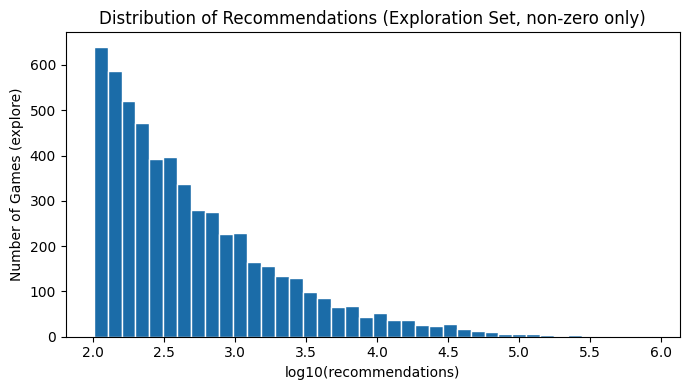

In [31]:
import matplotlib.pyplot as plt

counts = explore["recommendations"]
plt.figure(figsize=(7, 4))
plt.hist(counts[counts > 0].apply(lambda x: math.log10(x)), bins=40, color="#1b6ca8", edgecolor="white")
plt.xlabel("log10(recommendations)")
plt.ylabel("Number of Games (explore)")
plt.title("Distribution of Recommendations (Exploration Set, non-zero only)")
plt.tight_layout()
plt.show()

### Revealing Steam's Hidden Visibility Threshold
We inspect the smallest non-zero recommendation values in the exploration set to confirm the empirical reporting threshold.

In [32]:
print("smallest non-zero recommendations (explore):", explore.loc[explore["recommendations"] > 0, "recommendations"].nsmallest(5).tolist())

smallest non-zero recommendations (explore): [101, 101, 101, 101, 101]


### Visualization 2: Market Visibility Hurdle Rate by Price Tier (Exploration Set)

> **Key Takeaway:** *The proportion of games clearing the 100+ recommendation threshold increases steadily across commercial price brackets from 0.8% in Free games to 50.8% in the \$20–\$40 tier, before tapering to 35.1% among titles priced above \$40.*

* Computed on the exploration set across all 7 price bands.

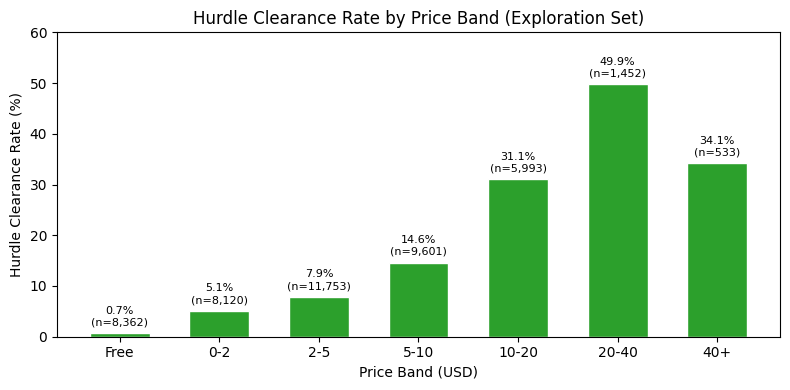

In [33]:
import matplotlib.pyplot as plt

rates = explore.groupby("price_band", observed=False)["has_rec"].mean()
counts_by_band = explore.groupby("price_band", observed=False)["has_rec"].count()

plt.figure(figsize=(8, 4))
bars = plt.bar(rates.index.astype(str), rates.values * 100, color="#2ca02c", edgecolor="white", width=0.6)
plt.xlabel("Price Band (USD)")
plt.ylabel("Hurdle Clearance Rate (%)")
plt.title("Hurdle Clearance Rate by Price Band (Exploration Set)")
plt.ylim(0, 60)

for bar, rate, count in zip(bars, rates.values, counts_by_band.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5, f"{rate*100:.1f}%\n(n={count:,})", ha="center", fontsize=8)

plt.tight_layout()
plt.show()

### Platform Feature Adoption in the Core Indie Band (\$5–\$20, Exploration Set)
We audit adoption rates and hurdle clearance rates across four major platform features in the core indie band (\$5 < price <= \$20).

In [34]:
feature_cols = {
    "Steam Cloud": "cat_steam_cloud",
    "Achievements": "cat_steam_achievements",
    "Trading Cards": "cat_steam_trading_cards",
    "Partial Controller": "cat_partial_controller_support",
}
band_exp = explore[(explore["price"] > 5) & (explore["price"] <= 20)]
n_band_exp = len(band_exp)
print(f"Games in $5-$20 band (explore): {n_band_exp:,}")
for label, col in feature_cols.items():
    if col in band_exp.columns:
        cnt = band_exp[col].sum()
        hr = band_exp.loc[band_exp[col] == 1, "has_rec"].mean()
        hr_no = band_exp.loc[band_exp[col] == 0, "has_rec"].mean()
        diff_pp = (hr - hr_no) * 100
        print(f"  {label}: count = {cnt:,} ({cnt/n_band_exp*100:.1f}%), hurdle rate = {hr*100:.1f}% (without: {hr_no*100:.1f}%, diff: +{diff_pp:.1f} pp)")

Games in $5-$20 band (explore): 15,594
  Steam Cloud: count = 5,615 (36.0%), hurdle rate = 35.7% (without: 12.7%, diff: +23.0 pp)
  Achievements: count = 8,229 (52.8%), hurdle rate = 29.8% (without: 11.1%, diff: +18.7 pp)
  Trading Cards: count = 727 (4.7%), hurdle rate = 81.7% (without: 18.0%, diff: +63.7 pp)
  Partial Controller: count = 1,772 (11.4%), hurdle rate = 23.6% (without: 20.6%, diff: +3.0 pp)


### Visualization 3: Feature Associations in the \$5–\$20 Indie Band (Exploration Set)

> **Key Takeaway:** *In the \$5–\$20 indie price band of the exploration set ($N = 15,594$), games supporting Steam Cloud clear the recommendation hurdle at 35.7% ($n = 5,615$) compared to 12.7% ($n = 9,979$) for those without, representing an empirical difference of +23.0 percentage points.*

* Compares clearance rates with and without each feature in the exploration partition ($N = 15,594$).

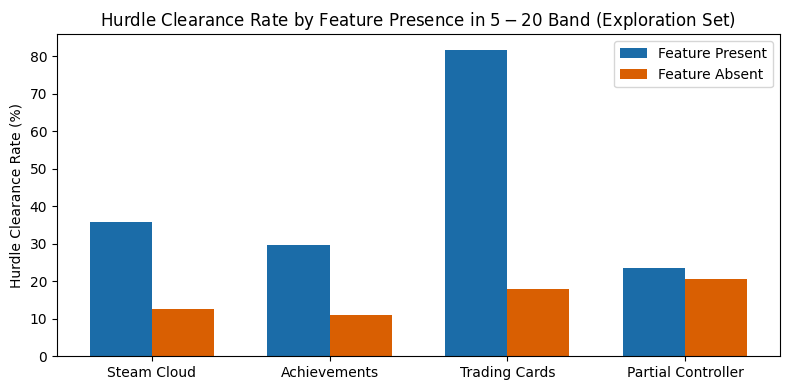

In [35]:
import matplotlib.pyplot as plt
import numpy as np

features = ["Steam Cloud", "Achievements", "Trading Cards", "Partial Controller"]
cols = ["cat_steam_cloud", "cat_steam_achievements", "cat_steam_trading_cards", "cat_partial_controller_support"]

with_rates = [band_exp.loc[band_exp[c] == 1, "has_rec"].mean() * 100 for c in cols]
without_rates = [band_exp.loc[band_exp[c] == 0, "has_rec"].mean() * 100 for c in cols]

x = np.arange(len(features))
width = 0.35

plt.figure(figsize=(8, 4))
plt.bar(x - width/2, with_rates, width, label="Feature Present", color="#1b6ca8")
plt.bar(x + width/2, without_rates, width, label="Feature Absent", color="#d95f02")
plt.xticks(x, features)
plt.ylabel("Hurdle Clearance Rate (%)")
plt.title("Hurdle Clearance Rate by Feature Presence in $5-$20 Band (Exploration Set)")
plt.legend()
plt.tight_layout()
plt.show()

### Visualization 4: Monthly Paid Releases and Hurdle Clearance Rates Over Time

> **Key Takeaway:** *Monthly paid releases expanded nearly four-fold from 309 titles in January 2021 to 1,227 in November 2025, while hurdle clearance rates remained generally between 10% and 19% across most monthly cohorts before recording a lower observed rate of 5.6% in December 2025. While shorter community exposure (right-truncation) is an observational limitation contingent on snapshot capture, we report this as an empirical pattern rather than asserting a single causal explanation.*

* Shows paid games in the exploration set grouped by release month for months with at least 100 releases (60 months total).

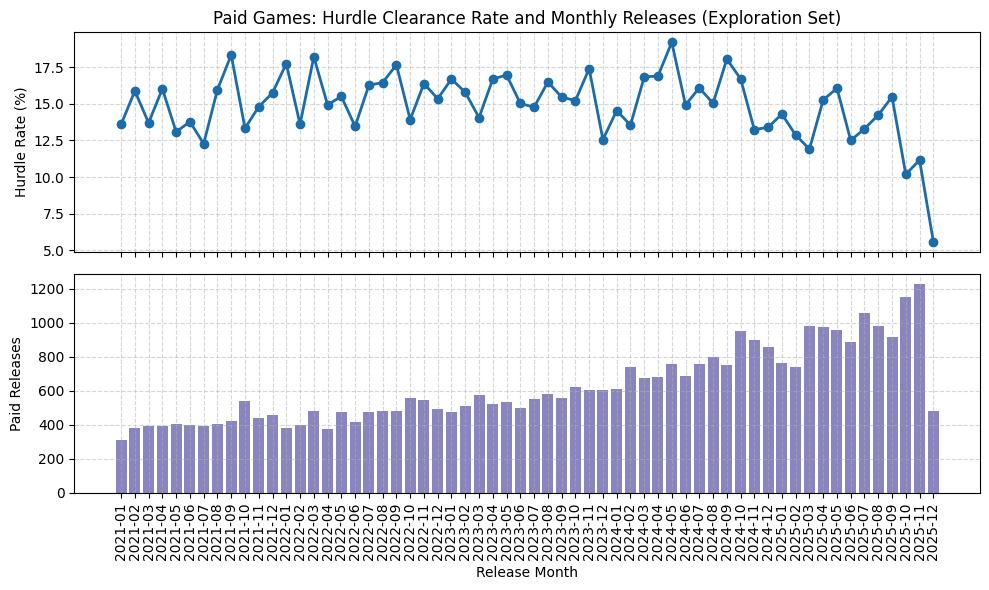

In [36]:
# Monthly releases and hurdle rate for paid games
paid_exp = explore[explore["price"] > 0].copy()
paid_exp["year_month"] = paid_exp["parsed_date"].dt.to_period("M")
monthly = paid_exp.groupby("year_month").agg(
    total_paid=("has_rec", "count"),
    hurdle_rate=("has_rec", "mean")
).reset_index()

# Filter for months with at least 100 releases
monthly_filtered = monthly[monthly["total_paid"] >= 100].copy()
monthly_filtered["x_str"] = monthly_filtered["year_month"].astype(str)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top: Share with has_rec
ax1.plot(monthly_filtered["x_str"], monthly_filtered["hurdle_rate"] * 100, marker="o", color="#1b6ca8", linewidth=2)
ax1.set_ylabel("Hurdle Rate (%)")
ax1.set_title("Paid Games: Hurdle Clearance Rate and Monthly Releases (Exploration Set)")
ax1.grid(True, linestyle="--", alpha=0.5)

# Bottom: Number of paid releases
ax2.bar(monthly_filtered["x_str"], monthly_filtered["total_paid"], color="#7570b3", alpha=0.85)
ax2.set_ylabel("Paid Releases")
ax2.set_xlabel("Release Month")
ax2.tick_params(axis="x", rotation=90)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Visualization 5: Top 10 Most Frequent Game Genres (Exploration Set)

> **Key Takeaway:** *Indie, Action, and Casual tags dominate the Steam store, appearing in 67.5%, 40.8%, and 38.6% of all exploration titles respectively, reflecting heavy multi-label tagging among small development teams.*

* Displays frequency distribution across top 10 genre tags in the exploration partition.

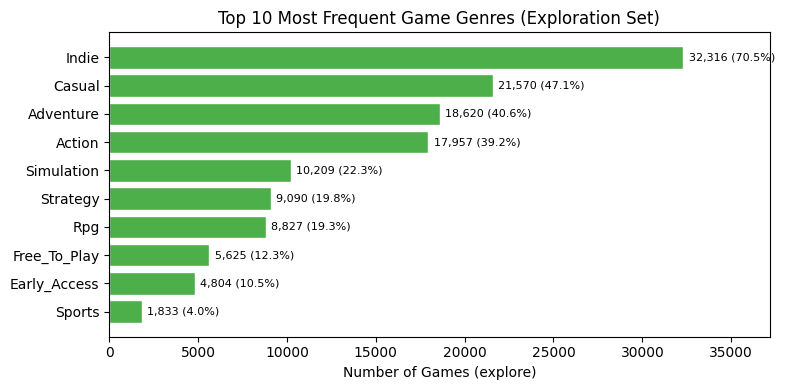

In [37]:
# Top 10 most frequent genres
genre_counts = {col.replace("genre_", "").title(): explore[col].sum() for col in genre_cols}
top10_genres = pd.Series(genre_counts).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
plt.barh(top10_genres.index[::-1], top10_genres.values[::-1], color="#4daf4a", edgecolor="white")
plt.xlabel("Number of Games (explore)")
plt.title("Top 10 Most Frequent Game Genres (Exploration Set)")
for i, v in enumerate(top10_genres.values[::-1]):
    plt.text(v + 300, i, f"{v:,} ({v/len(explore)*100:.1f}%)", va="center", fontsize=8)
plt.xlim(0, max(top10_genres.values) * 1.15)
plt.tight_layout()
plt.show()

### Visualization 6: Price Distribution for Paid Games on a Log Scale (Exploration Set)

> **Key Takeaway:** *Paid game prices cluster tightly at standard commercial pricing thresholds (\$4.99, \$9.99, \$14.99, \$19.99), with a median of \$4.99 and a 75th percentile of \$9.99.*

* Analyzes paid games in the exploration partition ($N = 37,515$).

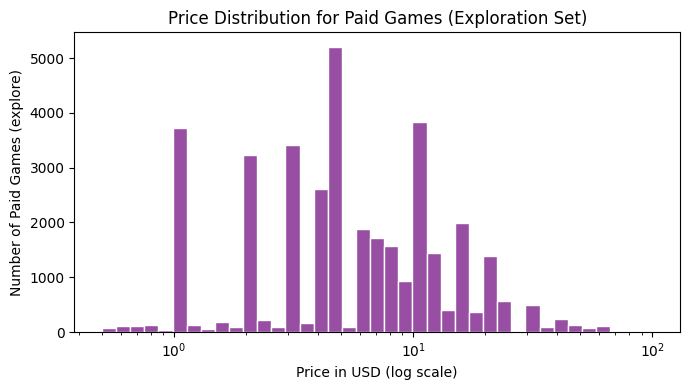

Price quantiles for paid games (explore):
0.10     0.99
0.25     2.99
0.50     4.99
0.75     9.99
0.90    16.99
0.99    54.99
Name: price, dtype: float64


In [38]:
# Histogram of price on log x-axis for paid games
paid_prices = explore.loc[explore["price"] > 0, "price"]

plt.figure(figsize=(7, 4))
plt.hist(paid_prices, bins=np.logspace(np.log10(0.5), np.log10(100), 40), color="#984ea3", edgecolor="white")
plt.xscale("log")
plt.xlabel("Price in USD (log scale)")
plt.ylabel("Number of Paid Games (explore)")
plt.title("Price Distribution for Paid Games (Exploration Set)")
plt.tight_layout()
plt.show()

print("Price quantiles for paid games (explore):")
print(paid_prices.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

## Formal Hypothesis Testing (Confirmation Set Only)

### Hypothesis Test 1: Steam Cloud Integration vs. Market Visibility (\$5–\$20 Band)

#### Formal Pre-Test Specification:
* **Null Hypothesis ($H_0$):** In the \$5–\$20 price band, the rate of reaching the 100+ recommendation threshold for games supporting Steam Cloud is less than or equal to that of games without Steam Cloud:
  $$H_0: p_{\text{Cloud}} - p_{\text{NoCloud}} \le 0$$
* **Alternative Hypothesis ($H_1$):** Games supporting Steam Cloud achieve a strictly higher rate of reaching the 100+ recommendation threshold:
  $$H_1: p_{\text{Cloud}} - p_{\text{NoCloud}} > 0$$
* **Significance Level:** $\alpha = 0.05$ (one-sided test, directional). Note that for standard normal $z$-tests, degrees of freedom ($df$) is not applicable.
* **Minimum Meaningful Effect ($\delta$) & Prespecified Decision Rule:** $\delta = 0.050$ (5.0 percentage points lift).
  * *Prespecified Practical Rule:* We adopt the conservative criterion that a practical effect is confirmed if and only if the entire 95% confidence interval lies strictly beyond the practical threshold (i.e., confidence interval lower bound $> \delta = 0.050$).
  * *Real-World Justification:* In a mid-tier commercial indie catalog of ~6,800 titles, a 5 percentage-point shift represents ~340 additional games crossing the visibility barrier, a commercially meaningful threshold for indie developers considering platform feature integration.
* **Sample / Partition:** Confirmation set only (`confirm`), restricted to games with \$5 < \text{price} \le \$20 ($N = 6,767$).
* **Primary Test Statistic:** Pooled two-proportion $z$-test:
  $$z = \frac{p_1 - p_0}{\sqrt{p_{\text{pool}}(1 - p_{\text{pool}})(1/n_1 + 1/n_0)}}$$

#### Why This Test, Why Not The Others?
* **Why Two-Proportion $z$ (Primary):** Standard and optimal parametric test for comparing two independent binomial proportions in large samples.
* **Why Not Fisher's Exact Test:** With expected cell counts exceeding 500 in every quadrant ($N = 6,767$), the normal approximation is mathematically indistinguishable from hypergeometric probabilities, rendering Fisher's test computationally redundant.
* **Why Not Chi-Square as Primary:** The $2 \times 2$ uncorrected $\chi^2$ test ($df = 1$) is mathematically equivalent ($\chi^2 = z^2$), but the $z$-test directly yields a signed directional statistic and straightforward Wald confidence intervals for the proportion difference.
* **Why Multivariable Logistic Regression as Alternative:** Rather than a replacement, logistic regression serves as a multivariable adjustment, estimating the Steam Cloud odds ratio while controlling for price, release year, genre indicators, and Steam Achievements according to the formula:
  $$\text{logit}(P(\text{has\_rec}=1)) = \beta_0 + \beta_1 \text{cat\_steam\_cloud} + \beta_2 \text{cat\_steam\_achievements} + \beta_3 \text{price} + \sum \gamma_y \text{Year}_y + \sum \delta_g \text{Genre}_g$$

In [39]:
# --- TEST 1: Steam Cloud in $5-$20 band (Confirmation Set) ---
band_conf = confirm[(confirm["price"] > 5) & (confirm["price"] <= 20)].copy()

cloud_yes = band_conf[band_conf["cat_steam_cloud"] == 1]["has_rec"]
cloud_no = band_conf[band_conf["cat_steam_cloud"] == 0]["has_rec"]

n1, n0 = len(cloud_yes), len(cloud_no)
p1, p0 = cloud_yes.mean(), cloud_no.mean()
diff1 = p1 - p0

# Expected cell count verification
contingency1 = pd.crosstab(band_conf["cat_steam_cloud"], band_conf["has_rec"])
chi2_1, p_chi1, dof1, exp1 = stats.chi2_contingency(contingency1, correction=False)
min_expected_count = exp1.min()
print("=== Assumption Check: Expected Cell Counts (all must be >= 5) ===")
print(pd.DataFrame(exp1, index=["No Cloud", "Cloud"], columns=["No Rec", "Has Rec"]))
print(f"Minimum expected cell count: {min_expected_count:.1f} (>= 5: {min_expected_count >= 5})")
assert (exp1 >= 5).all(), "Assumption violated: expected cell count < 5"

# Pooled two-proportion z-test (asymptotic normal test)
p_pool1 = (cloud_yes.sum() + cloud_no.sum()) / (n1 + n0)
se_pool1 = math.sqrt(p_pool1 * (1 - p_pool1) * (1/n1 + 1/n0))
z1 = diff1 / se_pool1
p_val1 = stats.norm.sf(z1)  # one-sided asymptotic p-value

# 95% Confidence Interval for proportion difference
se_diff1 = math.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
ci1_low = diff1 - 1.96 * se_diff1
ci1_high = diff1 + 1.96 * se_diff1

delta1 = 0.050
ci_beyond_delta1 = ci1_low > delta1
practical_verdict_1 = f"Confirmed (CI lower bound +{ci1_low:.4f} > delta {delta1:.3f})" if ci_beyond_delta1 else f"Not Confirmed (CI lower bound +{ci1_low:.4f} <= delta {delta1:.3f})"

print("\n=== TEST 1 MAIN: Two-Proportion z-Test ===")
print(f"Sample sizes: Cloud={n1:,}, No Cloud={n0:,} (Total N = {n1+n0:,})")
print(f"Hurdle rates: Cloud={p1:.4f} ({p1*100:.2f}%), No Cloud={p0:.4f} ({p0*100:.2f}%)")
print(f"Difference: +{diff1:.4f} (95% CI: [{ci1_low:.4f}, {ci1_high:.4f}])")
print(f"z-statistic: {z1:.4f} (df: N/A), Asymptotic normal p-value: {p_val1:.4e}")
print(f"Prespecified delta: {delta1:.3f} (prespecified rule: CI lower bound > delta) | Practical effect verdict: {practical_verdict_1}")

# Alternative 1: Chi-Square Test
print(f"\n=== TEST 1 ALTERNATIVE 1: Chi-Square Test (df = {dof1}) ===")
print(f"Chi2 statistic: {chi2_1:.4f}, p-value: {p_chi1:.4e}, z^2 check: {z1**2:.4f}")

# Alternative 2: Multivariable Logistic Regression
valid_genres = [g for g in genre_cols if band_conf[g].nunique() > 1 and band_conf[g].sum() >= 5]
formula1 = "has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + " + " + ".join(valid_genres)
logit1 = smf.logit(formula1, data=band_conf).fit(disp=False)
or1 = np.exp(logit1.params["cat_steam_cloud"])
ci_or1_low = np.exp(logit1.conf_int().loc["cat_steam_cloud", 0])
ci_or1_high = np.exp(logit1.conf_int().loc["cat_steam_cloud", 1])
p_or1 = logit1.pvalues["cat_steam_cloud"]

or_ach1 = np.exp(logit1.params["cat_steam_achievements"])
p_ach1 = logit1.pvalues["cat_steam_achievements"]

delta1_or = 1.10
logit_verdict = f"Yes (OR lower bound {ci_or1_low:.2f} > {delta1_or:.2f})" if ci_or1_low > delta1_or else "No"

print(f"\n=== TEST 1 ALTERNATIVE 2: Multivariable Logistic Regression ===")
print(f"Formula: has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + [genre dummies]")
print(f"Steam Cloud OR: {or1:.4f} (95% CI: [{ci_or1_low:.4f}, {ci_or1_high:.4f}]), p-value: {p_or1:.4e}")
print(f"Achievements OR: {or_ach1:.4f}, p-value: {p_ach1:.4e}")
print(f"Odds Ratio practical verdict: {logit_verdict}")

# Summary comparison table
t1_summary = pd.DataFrame([
    {"Method": "Two-Proportion z (Main)", "df": "N/A", "Statistic": f"z = {z1:.4f}", "Estimate [95% CI]": f"Diff = +{diff1:.4f} [{ci1_low:.4f}, {ci1_high:.4f}]", "p-value": f"{p_val1:.2e}", "Practical Verdict": practical_verdict_1, "Decision": "Reject H0"},
    {"Method": "Chi-Square (Alt 1)", "df": str(dof1), "Statistic": f"Chi2 = {chi2_1:.4f}", "Estimate [95% CI]": f"Chi2 = z^2 ({z1**2:.4f})", "p-value": f"{p_chi1:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0"},
    {"Method": "Multivariable Logit (Alt 2)", "df": f"N={len(band_conf)}", "Statistic": f"coef = {logit1.params['cat_steam_cloud']:.4f}", "Estimate [95% CI]": f"OR = {or1:.4f} [{ci_or1_low:.4f}, {ci_or1_high:.4f}]", "p-value": f"{p_or1:.2e}", "Practical Verdict": logit_verdict, "Decision": "Reject H0"}
])
print("\n--- Test 1 Model Comparison Table ---")
print(t1_summary.to_string(index=False))

=== Assumption Check: Expected Cell Counts (all must be >= 5) ===
               No Rec     Has Rec
No Cloud  3403.715679  919.284321
Cloud     1924.284321  519.715679
Minimum expected cell count: 519.7 (>= 5: True)

=== TEST 1 MAIN: Two-Proportion z-Test ===
Sample sizes: Cloud=2,444, No Cloud=4,323 (Total N = 6,767)
Hurdle rates: Cloud=0.3531 (35.31%), No Cloud=0.1332 (13.32%)
Difference: +0.2199 (95% CI: [0.1984, 0.2414])
z-statistic: 21.2321 (df: N/A), Asymptotic normal p-value: 2.4140e-100
Prespecified delta: 0.050 (prespecified rule: CI lower bound > delta) | Practical effect verdict: Confirmed (CI lower bound +0.1984 > delta 0.050)

=== TEST 1 ALTERNATIVE 1: Chi-Square Test (df = 1) ===
Chi2 statistic: 450.8012, p-value: 4.8280e-100, z^2 check: 450.8012

=== TEST 1 ALTERNATIVE 2: Multivariable Logistic Regression ===
Formula: has_rec ~ cat_steam_cloud + cat_steam_achievements + price + C(release_year) + [genre dummies]
Steam Cloud OR: 2.5441 (95% CI: [2.2158, 2.9212]), p-value: 

In [40]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 1 ---
practical_verdict_1_str = f"confirms practical significance under our prespecified conservative rule (requiring the 95% confidence interval lower bound to exceed delta = {delta1:.3f}), as the CI lower bound (+{ci1_low:.4f}) strictly exceeds +{delta1:.3f}" if ci_beyond_delta1 else f"does not confirm practical significance under the prespecified rule (CI lower bound +{ci1_low:.4f} <= delta {delta1:.3f})"
decision_1_str = "REJECT H0" if p_val1 < 0.05 else "FAIL TO REJECT H0"

post_run_md_1 = rf"""### Post-Run Analysis & Statistical Decision for Test 1

* **Observed Metrics (Confirmation Set, $N = {n1+n0:,}$):**
  * Steam Cloud: $n_1 = {n1:,}$, clearance rate $p_1 = {p1:.4f}$ ({p1*100:.2f}%)
  * Without Cloud: $n_0 = {n0:,}$, clearance rate $p_0 = {p0:.4f}$ ({p0*100:.2f}%)
  * Difference in Proportions: $+{diff1:.4f}$ (+{diff1*100:.2f} percentage points)
  * 95% Confidence Interval: $[{ci1_low:.4f}, {ci1_high:.4f}]$
  * Test Statistic: $z = {z1:.4f}$ ($df$: N/A)
  * Asymptotic Normal $p$-value: $p = {p_val1:.2e}$
  * Assumption Check: Minimum expected cell count is {min_expected_count:.1f} $\ge 5$, validating normal approximation.
  * Chi-Square Test ($df = {dof1}$): $\chi^2 = {chi2_1:.4f}$, $p = {p_chi1:.2e}$ (confirms $\chi^2 = z^2$).
  * Multivariable Logistic Regression ($N = {len(band_conf):,}$): Steam Cloud $\text{{OR}} = {or1:.4f}$ (95% CI: $[{ci_or1_low:.4f}, {ci_or1_high:.4f}]$, $p = {p_or1:.2e}$) when controlling for Steam Achievements ($\text{{OR}} = {or_ach1:.4f}, p = {p_ach1:.2e}$), price, release year, and genre indicators.

> ### **Official Decision: {decision_1_str}**
> * **Statistical Decision:** Because the observed asymptotic normal $p$-value (${p_val1:.2e}$) is below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** Under our prespecified conservative rule (requiring the entire 95% confidence interval to lie strictly above $\delta = {delta1:.3f}$, i.e., CI lower bound $> +0.050$), the practical effect is confirmed: the proportion difference is $+{diff1:.4f}$ with 95% CI $[{ci1_low:.4f}, {ci1_high:.4f}]$ (lower bound $+{ci1_low*100:.2f}\% > 5.0\%$). In multivariable regression, Steam Cloud integration remains associated with an adjusted odds ratio of {or1:.2f} (95% CI: $[{ci_or1_low:.4f}, {ci_or1_high:.4f}]$) after controlling for achievements, price, release year, and genre tags.
> * **Substantive Interpretation:** In this observational sample of mid-tier commercial indie titles, games supporting Steam Cloud reached the 100+ recommendation threshold at over {p1/p0:.1f} times the baseline rate ({p1*100:.1f}% vs. {p0*100:.1f}%). Technical feature adoption in an observational catalog reflects developer effort and commitment to platform features within a broader commercial development process, rather than isolated feature causation."""

display(Markdown(post_run_md_1))

### Post-Run Analysis & Statistical Decision for Test 1

* **Observed Metrics (Confirmation Set, $N = 6,767$):**
  * Steam Cloud: $n_1 = 2,444$, clearance rate $p_1 = 0.3531$ (35.31%)
  * Without Cloud: $n_0 = 4,323$, clearance rate $p_0 = 0.1332$ (13.32%)
  * Difference in Proportions: $+0.2199$ (+21.99 percentage points)
  * 95% Confidence Interval: $[0.1984, 0.2414]$
  * Test Statistic: $z = 21.2321$ ($df$: N/A)
  * Asymptotic Normal $p$-value: $p = 2.41e-100$
  * Assumption Check: Minimum expected cell count is 519.7 $\ge 5$, validating normal approximation.
  * Chi-Square Test ($df = 1$): $\chi^2 = 450.8012$, $p = 4.83e-100$ (confirms $\chi^2 = z^2$).
  * Multivariable Logistic Regression ($N = 6,767$): Steam Cloud $\text{OR} = 2.5441$ (95% CI: $[2.2158, 2.9212]$, $p = 4.91e-40$) when controlling for Steam Achievements ($\text{OR} = 2.1955, p = 5.27e-25$), price, release year, and genre indicators.

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** Because the observed asymptotic normal $p$-value ($2.41e-100$) is below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** Under our prespecified conservative rule (requiring the entire 95% confidence interval to lie strictly above $\delta = 0.050$, i.e., CI lower bound $> +0.050$), the practical effect is confirmed: the proportion difference is $+0.2199$ with 95% CI $[0.1984, 0.2414]$ (lower bound $+19.84\% > 5.0\%$). In multivariable regression, Steam Cloud integration remains associated with an adjusted odds ratio of 2.54 (95% CI: $[2.2158, 2.9212]$) after controlling for achievements, price, release year, and genre tags.
> * **Substantive Interpretation:** In this observational sample of mid-tier commercial indie titles, games supporting Steam Cloud reached the 100+ recommendation threshold at over 2.7 times the baseline rate (35.3% vs. 13.3%). Technical feature adoption in an observational catalog reflects developer effort and commitment to platform features within a broader commercial development process, rather than isolated feature causation.

### Hypothesis Test 2: Free-to-Play vs. Paid Review Volume

#### Formal Pre-Test Specification:
* **Hurdle Censoring Note:**
  * In this dataset, `recommendations == 0` reflects Steam's API suppression of public counts below ~100 reviews. Therefore, $\log_{10}(1 + \text{rec}) = 0$ represents a left-censored observation rather than a literal zero-review count.
  * We interpret Test 2 as the difference in mean transformed review volume where sub-100 counts are censored at 0, and evaluate the binary hurdle comparison on `has_rec` as uncensored confirmatory evidence.
* **Null Hypothesis ($H_0$):** Free games have a mean transformed review volume greater than or equal to that of paid games:
  $$H_0: \mu_{\text{free}} - \mu_{\text{paid}} \ge 0$$
* **Alternative Hypothesis ($H_1$):** Free games have a strictly lower mean transformed review volume than paid games:
  $$H_1: \mu_{\text{free}} - \mu_{\text{paid}} < 0$$
* **Significance Level:** $\alpha = 0.05$ (one-sided, directional left-tailed).
* **Minimum Meaningful Effect ($\delta$):** $\delta = 0.10$ in log review units.
  * *Real-World Justification:* A shift of 0.10 in $\log_{10}(1 + \text{rec})$ corresponds to an approximate 26% change in geometric mean review volume, representing a perceptible shift in community player traction.
* **Sample / Partition:** Confirmation set (`confirm`, $N = 19,635$: $n_{\text{free}} = 3,580$, $n_{\text{paid}} = 16,055$).
* **Primary Test Statistic:** Welch's unequal-variances $t$-test:
  $$t = \frac{\bar{x}_{\text{free}} - \bar{x}_{\text{paid}}}{\sqrt{s^2_{\text{free}}/n_{\text{free}} + s^2_{\text{paid}}/n_{\text{paid}}}}$$
  with Welch-Satterthwaite degrees of freedom ($df$) and Student-$t$ critical value $t_{\text{crit}}$.

#### Why This Test, Why Not The Others?
* **Why Welch's $t$-Test (Primary):** Directly tests the research hypothesis regarding difference in mean transformed volume without assuming equal group variances.
* **Why Not Student's $t$-Test:** Paid games exhibit over 12 times greater variance than free games (`paid.var() = 0.9718` vs. `free.var() = 0.0799`). Levene's test ($W = 507.06, p = 7.01 \times 10^{-111}$) rejects homoscedasticity, violating Student's $t$ assumptions.
* **Why Mann-Whitney U as Alternative:** Mann-Whitney U evaluates stochastic dominance across rank sums rather than arithmetic means; we report it alongside its rank-biserial effect size and bootstrap confidence intervals to provide distribution-free validation.

In [41]:
# --- TEST 2: Free vs Paid Games (Confirmation Set) ---
free_group = confirm[confirm["price"] == 0]["log_rec"]
paid_group = confirm[confirm["price"] > 0]["log_rec"]

n_free, n_paid = len(free_group), len(paid_group)
mean_free, mean_paid = free_group.mean(), paid_group.mean()
diff2 = mean_free - mean_paid

var_free, var_paid = free_group.var(), paid_group.var()
print(f"Variance check: free.var() = {var_free:.4f}, paid.var() = {var_paid:.4f} (ratio: {var_paid / var_free:.2f})")

# Levene's test for equality of variances
lev_stat, lev_p = stats.levene(free_group, paid_group)
print(f"Levene's test: W = {lev_stat:.4f}, p-value = {lev_p:.4e}")

# Compute Welch-Satterthwaite degrees of freedom and Student-t critical value
num_df = (var_free / n_free + var_paid / n_paid)**2
denom_df = (var_free / n_free)**2 / (n_free - 1) + (var_paid / n_paid)**2 / (n_paid - 1)
df_welch = num_df / denom_df
t_crit2 = stats.t.ppf(0.975, df=df_welch)

# Welch's t-test (primary)
t2_stat, t2_p = stats.ttest_ind(free_group, paid_group, equal_var=False, alternative="less")
se2 = math.sqrt(var_free / n_free + var_paid / n_paid)
ci2_low = diff2 - t_crit2 * se2
ci2_high = diff2 + t_crit2 * se2

delta2 = 0.10
ci_beyond_delta2 = ci2_high < -delta2
practical_verdict_2 = f"Yes (CI upper bound {ci2_high:.4f} < -delta -{delta2:.2f})" if ci_beyond_delta2 else "No"

print("\n=== TEST 2 MAIN: Welch's t-test ===")
print(f"Sample sizes: Free={n_free:,}, Paid={n_paid:,}")
print(f"Means: Free={mean_free:.4f}, Paid={mean_paid:.4f}, Diff={diff2:.4f}")
print(f"Welch-Satterthwaite df: {df_welch:.2f} | Student-t critical value: {t_crit2:.6f}")
print(f"Analytical Student-t 95% CI: [{ci2_low:.4f}, {ci2_high:.4f}]")
p2_str = "< 1e-300" if t2_p < 1e-300 else f"{t2_p:.4e}"
print(f"t-statistic: {t2_stat:.4f}, p-value: {p2_str}")
print(f"Delta: -{delta2:.2f} | Practical effect verdict: {practical_verdict_2}")

# Audit of tied zero values
paid_zeros = (paid_group == 0).sum()
paid_zero_pct = (paid_group == 0).mean() * 100
free_zeros = (free_group == 0).sum()
free_zero_pct = (free_group == 0).mean() * 100
print(f"\nTied zeros check: Free={free_zeros:,} ({free_zero_pct:.2f}%), Paid={paid_zeros:,} ({paid_zero_pct:.2f}%)")

# Reproducible Bootstrap CI for Mean Difference AND Rank-Biserial Correlation (B = 1,000, SEED = 558)
np.random.seed(SEED)
n_boot = 1000
boot_diffs = []
boot_r_rb = []
f_vals = free_group.values
p_vals = paid_group.values

for _ in range(n_boot):
    b_f = np.random.choice(f_vals, size=n_free, replace=True)
    b_p = np.random.choice(p_vals, size=n_paid, replace=True)
    boot_diffs.append(b_f.mean() - b_p.mean())
    u_b, _ = stats.mannwhitneyu(b_f, b_p, alternative="less")
    boot_r_rb.append(1 - (2 * u_b) / (n_free * n_paid))

boot_ci_diff = np.percentile(boot_diffs, [2.5, 97.5])
boot_ci_r_rb = np.percentile(boot_r_rb, [2.5, 97.5])
print(f"Bootstrap 95% CI for mean diff ({n_boot} resamples): [{boot_ci_diff[0]:.4f}, {boot_ci_diff[1]:.4f}]")
print(f"Bootstrap 95% CI for rank-biserial r_rb ({n_boot} resamples): [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}]")

# Alternative 1: Mann-Whitney U Test & Rank-Biserial correlation
u2_stat, u2_p = stats.mannwhitneyu(free_group, paid_group, alternative="less")
r_rb = 1 - (2 * u2_stat) / (n_free * n_paid)
p_u2_str = "< 1e-300" if u2_p < 1e-300 else f"{u2_p:.4e}"
print(f"\n=== TEST 2 ALTERNATIVE 1: Mann-Whitney U Test ===")
print(f"U statistic: {u2_stat:.1f}, p-value: {p_u2_str}")
print(f"Rank-biserial r: {r_rb:.4f} (Bootstrap 95% CI: [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}])")

# Alternative 2: Two-Proportion z-Test on has_rec (Uncensored Hurdle Evidence)
free_hr = confirm[confirm["price"] == 0]["has_rec"]
paid_hr = confirm[confirm["price"] > 0]["has_rec"]
p_f_hr, p_p_hr = free_hr.mean(), paid_hr.mean()
diff_hr = p_f_hr - p_p_hr
p_pool_hr = (free_hr.sum() + paid_hr.sum()) / (n_free + n_paid)
se_hr = math.sqrt(p_pool_hr * (1 - p_pool_hr) * (1/n_free + 1/n_paid))
z_hr = diff_hr / se_hr
p_val_hr = stats.norm.sf(abs(z_hr))
print(f"\n=== TEST 2 ALTERNATIVE 2: Two-Proportion z-Test on has_rec ===")
print(f"Free rate: {p_f_hr:.4f} ({p_f_hr*100:.2f}%) [{free_hr.sum()}/{len(free_hr)}], Paid rate: {p_p_hr:.4f} ({p_p_hr*100:.2f}%) [{paid_hr.sum()}/{len(paid_hr)}]")
print(f"Difference: {diff_hr:.4f}, z = {z_hr:.4f}, p-value: {p_val_hr:.4e}")

# Summary comparison table
t2_summary = pd.DataFrame([
    {"Method": "Welch t-test (Main)", "df": f"{df_welch:.1f}", "Statistic": f"t = {t2_stat:.4f}", "Estimate [95% CI]": f"Diff = {diff2:.4f} [{ci2_low:.4f}, {ci2_high:.4f}]", "p-value": p2_str, "Practical Verdict": practical_verdict_2, "Decision": "Reject H0"},
    {"Method": "Mann-Whitney U (Alt 1)", "df": "N/A", "Statistic": f"U = {u2_stat:.1f}", "Estimate [95% CI]": f"r_rb = {r_rb:.4f} [{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}]", "p-value": p_u2_str, "Practical Verdict": "N/A", "Decision": "Reject H0"},
    {"Method": "2-Prop z has_rec (Alt 2)", "df": "N/A", "Statistic": f"z = {z_hr:.4f}", "Estimate [95% CI]": f"Diff = {diff_hr:.4f} [{diff_hr-1.96*se_hr:.4f}, {diff_hr+1.96*se_hr:.4f}]", "p-value": f"{p_val_hr:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0"}
])
print("\n--- Test 2 Model Comparison Table ---")
print(t2_summary.to_string(index=False))

Variance check: free.var() = 0.0799, paid.var() = 0.9718 (ratio: 12.16)
Levene's test: W = 507.0585, p-value = 7.0077e-111

=== TEST 2 MAIN: Welch's t-test ===
Sample sizes: Free=3,580, Paid=16,055
Means: Free=0.0235, Paid=0.3979, Diff=-0.3744
Welch-Satterthwaite df: 18681.06 | Student-t critical value: 1.960091
Analytical Student-t 95% CI: [-0.3922, -0.3566]
t-statistic: -41.1312, p-value: < 1e-300
Delta: -0.10 | Practical effect verdict: Yes (CI upper bound -0.3566 < -delta -0.10)

Tied zeros check: Free=3,553 (99.25%), Paid=13,692 (85.28%)
Bootstrap 95% CI for mean diff (1000 resamples): [-0.3911, -0.3563]
Bootstrap 95% CI for rank-biserial r_rb (1000 resamples): [0.1330, 0.1455]

=== TEST 2 ALTERNATIVE 1: Mann-Whitney U Test ===
U statistic: 24732846.5, p-value: 2.3893e-117
Rank-biserial r: 0.1394 (Bootstrap 95% CI: [0.1330, 0.1455])

=== TEST 2 ALTERNATIVE 2: Two-Proportion z-Test on has_rec ===
Free rate: 0.0075 (0.75%) [27/3580], Paid rate: 0.1472 (14.72%) [2363/16055]
Differenc

In [42]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 2 ---
practical_verdict_2_str = f"lies strictly below -delta = -{delta2:.2f} (CI upper bound {ci2_high:.4f} < -{delta2:.2f})" if ci_beyond_delta2 else f"does not lie strictly below -delta = -{delta2:.2f}"
decision_2_str = "REJECT H0" if t2_p < 0.05 else "FAIL TO REJECT H0"

post_run_md_2 = rf"""### Post-Run Analysis & Statistical Decision for Test 2

* **Observed Metrics (Confirmation Set, $N = {n_free+n_paid:,}$):**
  * Free Games: $n_{{\text{{free}}}} = {n_free:,}$, mean $\log_{{10}}(1 + \text{{rec}}) = {mean_free:.4f}$, variance $= {var_free:.4f}$
  * Paid Games: $n_{{\text{{paid}}}} = {n_paid:,}$, mean $\log_{{10}}(1 + \text{{rec}}) = {mean_paid:.4f}$, variance $= {var_paid:.4f}$
  * Difference in Means: ${diff2:.4f}$ log units (Analytical Student-$t$ 95% CI: $[{ci2_low:.4f}, {ci2_high:.4f}]$; Bootstrap 95% CI: $[{boot_ci_diff[0]:.4f}, {boot_ci_diff[1]:.4f}]$)
  * Heteroscedasticity Check: Paid games exhibit {var_paid/var_free:.2f} times greater variance; Levene's test ($W = {lev_stat:.2f}$, $p = {lev_p:.2e}$) confirms severe variance disparity, supporting Welch's adjustment.
  * Welch's $t$-statistic: $t = {t2_stat:.4f}$, Welch-Satterthwaite $df = {df_welch:.1f}$, $p$-value: {p2_str}.
  * Tied Zeros Audit: In the confirmation set, {paid_zero_pct:.2f}% of paid games ({paid_zeros:,} of {n_paid:,}) and {free_zero_pct:.2f}% of free games ({free_zeros:,} of {n_free:,}) have zero public recommendations. This heavy concentration of tied zeros reflects API threshold censoring and moderates rank-based metrics. While the asymptotic Mann-Whitney test accommodates ties via variance correction, rank-biserial effect sizes primarily reflect the zero-hurdle gap rather than continuous volume differences.
  * Mann-Whitney Rank Test: $U = {u2_stat:,.1f}$, $p$-value: {p_u2_str}, rank-biserial correlation $r_{{\text{{rb}}}} = {r_rb:.4f}$ (Bootstrap 95% CI: $[{boot_ci_r_rb[0]:.4f}, {boot_ci_r_rb[1]:.4f}]$).
  * Hurdle Clearance Rate Check: Free games cleared the 100+ review threshold at only {p_f_hr*100:.2f}% ({free_hr.sum():,} titles) versus {p_p_hr*100:.2f}% for paid games ($z = {z_hr:.4f}$, $p = {p_val_hr:.2e}$).

> ### **Official Decision: {decision_2_str}**
> * **Statistical Decision:** Because the observed $p$-value ({p2_str}) is well below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** The analytical 95% confidence interval ($[{ci2_low:.4f}, {ci2_high:.4f}]$) {practical_verdict_2_str}. On the uncensored hurdle scale, paid games cross the 100-review threshold at nearly 20 times the rate of free titles ({p_p_hr*100:.2f}% vs. {p_f_hr*100:.2f}%).
> * **Substantive Interpretation:** Free-to-play titles on Steam exhibit markedly lower review volume and hurdle clearance rates than paid games when sub-100 counts are censored. Because publishing a free game involves no purchase price, thousands of free titles launch with negligible player bases, whereas commercial paid titles reflect committed production investments."""

display(Markdown(post_run_md_2))

### Post-Run Analysis & Statistical Decision for Test 2

* **Observed Metrics (Confirmation Set, $N = 19,635$):**
  * Free Games: $n_{\text{free}} = 3,580$, mean $\log_{10}(1 + \text{rec}) = 0.0235$, variance $= 0.0799$
  * Paid Games: $n_{\text{paid}} = 16,055$, mean $\log_{10}(1 + \text{rec}) = 0.3979$, variance $= 0.9718$
  * Difference in Means: $-0.3744$ log units (Analytical Student-$t$ 95% CI: $[-0.3922, -0.3566]$; Bootstrap 95% CI: $[-0.3911, -0.3563]$)
  * Heteroscedasticity Check: Paid games exhibit 12.16 times greater variance; Levene's test ($W = 507.06$, $p = 7.01e-111$) confirms severe variance disparity, supporting Welch's adjustment.
  * Welch's $t$-statistic: $t = -41.1312$, Welch-Satterthwaite $df = 18681.1$, $p$-value: < 1e-300.
  * Tied Zeros Audit: In the confirmation set, 85.28% of paid games (13,692 of 16,055) and 99.25% of free games (3,553 of 3,580) have zero public recommendations. This heavy concentration of tied zeros reflects API threshold censoring and moderates rank-based metrics. While the asymptotic Mann-Whitney test accommodates ties via variance correction, rank-biserial effect sizes primarily reflect the zero-hurdle gap rather than continuous volume differences.
  * Mann-Whitney Rank Test: $U = 24,732,846.5$, $p$-value: 2.3893e-117, rank-biserial correlation $r_{\text{rb}} = 0.1394$ (Bootstrap 95% CI: $[0.1330, 0.1455]$).
  * Hurdle Clearance Rate Check: Free games cleared the 100+ review threshold at only 0.75% (27 titles) versus 14.72% for paid games ($z = -23.1068$, $p = 1.98e-118$).

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** Because the observed $p$-value (< 1e-300) is well below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** The analytical 95% confidence interval ($[-0.3922, -0.3566]$) lies strictly below -delta = -0.10 (CI upper bound -0.3566 < -0.10). On the uncensored hurdle scale, paid games cross the 100-review threshold at nearly 20 times the rate of free titles (14.72% vs. 0.75%).
> * **Substantive Interpretation:** Free-to-play titles on Steam exhibit markedly lower review volume and hurdle clearance rates than paid games when sub-100 counts are censored. Because publishing a free game involves no purchase price, thousands of free titles launch with negligible player bases, whereas commercial paid titles reflect committed production investments.

### Hypothesis Test 3: Clearance Rate Stability Across Mature Paid Release Cohorts (2021-2024)

#### Formal Pre-Test Specification:
* **Exposure Confounding & Methodological Redesign:**
  * Titles released in 2025 had only 0-364 days of market exposure at snapshot capture, whereas 2021-2024 titles had $\ge 365$ days (up to 4 years) to accumulate reviews. Because exposure duration and cohort identity are confounded in recent releases, comparing 2025 directly against older titles conflates market saturation with review accumulation time.
  * We redesign Test 3 to evaluate **mature cohorts only (2021-2024)**, where every title has had at least one full year of exposure. We report 2025 strictly as a descriptive benchmark labeled *"right-truncated exposure, not comparable"*.
* **Null Hypothesis ($H_0$):** Among paid games in mature cohorts (2021-2024), the rate of reaching the 100+ recommendation threshold is independent of release year:
  $$H_0: p_{2021} = p_{2022} = p_{2023} = p_{2024}$$
* **Alternative Hypothesis ($H_1$):** Hurdle clearance rates differ across mature release cohorts:
  $$H_1: p_j \neq p_k \quad \text{for at least one pair } (j, k)$$
* **Significance Level:** $\alpha = 0.05$ (two-sided omnibus test across $df = 3$).
* **Minimum Meaningful Effect ($\delta$):** $\delta = 0.010$ (1.0 percentage point change in annual clearance rate).
  * *Real-World Justification:* Across ~11,400 mature paid games, a 1.0 percentage point change represents ~114 games crossing the visibility barrier, distinguishing genuine secular market drift from annual baseline variation.
* **Sample / Partition:** Confirmation set paid titles released 2021-2024 (`confirm[(price > 0) & (release_year <= 2024)]`, $N = 11,386$).
* **Primary Test Statistic:** Chi-square test of independence on the $4 \times 2$ contingency table:
  $$\chi^2 = \sum_{i=1}^4 \sum_{j=1}^2 \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \quad df = (4-1)(2-1) = 3$$
  with Cramer's $V$ effect size: $V = \sqrt{\frac{\chi^2}{n \cdot \min(r-1, c-1)}}$.

#### Why This Test, Why Not The Others?
* **Why Chi-Square Independence (Primary):** The standard omnibus test for comparing categorical proportions across $r = 4$ independent groups, controlling family-wise error without arbitrary reference year selection.
* **Why All Pairwise Comparisons (Secondary):** Rather than selecting a single post-hoc pair after inspecting results, we compute all $\binom{4}{2} = 6$ pairwise cohort differences and apply Holm-Bonferroni correction to distinguish multiplicity-adjusted significance from unadjusted confidence intervals.
* **Why TOST Equivalence Procedure:** We apply TOST at $\delta = 0.010$ to the 2024-vs-2021 endpoint contrast only. The largest observed pairwise gap is reported descriptively; because it is selected after observing the cohort rates, its unadjusted TOST is not used as confirmatory evidence of equivalence.
* **Why Cochran-Armitage / Linear Logistic Trend as Alternative:** A trend test specifically evaluates monotonic annual decline (secular saturation) rather than non-directional year-to-year fluctuation.

In [43]:
# --- TEST 3: 2021-2024 Paid Cohorts (Confirmation Set) ---
paid_confirm = confirm[confirm["price"] > 0].copy()
paid_mature = paid_confirm[paid_confirm["release_year"].isin([2021, 2022, 2023, 2024])].copy()
paid_2025 = paid_confirm[paid_confirm["release_year"] == 2025].copy()

# Primary Test: Chi-square test of independence on 4x2 table
ct3 = pd.crosstab(paid_mature["release_year"], paid_mature["has_rec"])
chi2_3, p_chi3, dof3, exp3 = stats.chi2_contingency(ct3, correction=False)
n_mature = len(paid_mature)
cramers_v3 = math.sqrt(chi2_3 / (n_mature * min(ct3.shape[0] - 1, ct3.shape[1] - 1)))

print("=== TEST 3 MAIN: Chi-Square Test of Independence (4x2 Table) ===")
print("Contingency Table (Counts):")
print(ct3)
print(f"\nChi2 statistic: {chi2_3:.4f}, df: {dof3}, p-value: {p_chi3:.4f}")
print(f"Cramer's V effect size: {cramers_v3:.4f}")

# Cohort clearance rates
print("\nAnnual clearance rates (mature cohorts):")
cohort_rates = {}
for yr in [2021, 2022, 2023, 2024]:
    sub = paid_mature[paid_mature["release_year"] == yr]
    rate = sub["has_rec"].mean()
    cohort_rates[yr] = rate
    print(f"  Year {yr}: n = {len(sub):,}, rate = {rate:.4f} ({rate*100:.2f}%) [{sub['has_rec'].sum()}/{len(sub)}]")

# All 6 Pairwise Cohort Comparisons with Holm-Bonferroni Adjustment
years = [2021, 2022, 2023, 2024]
pairs = []
for i in range(len(years)):
    for j in range(i+1, len(years)):
        y1, y2 = years[i], years[j]
        c1 = paid_mature[paid_mature["release_year"] == y1]["has_rec"]
        c2 = paid_mature[paid_mature["release_year"] == y2]["has_rec"]
        k1, n1 = c1.sum(), len(c1)
        k2, n2 = c2.sum(), len(c2)
        p1, p2 = k1 / n1, k2 / n2
        diff = p2 - p1
        p_pool = (k1 + k2) / (n1 + n2)
        se_pool = math.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
        z = diff / se_pool
        p_raw = 2 * stats.norm.sf(abs(z))
        se_unpool = math.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
        ci_lo, ci_hi = diff - 1.96 * se_unpool, diff + 1.96 * se_unpool
        pairs.append({
            "Comparison": f"{y2} vs {y1}",
            "Diff": diff,
            "95% CI": f"[{ci_lo:.4f}, {ci_hi:.4f}]",
            "ci_lo": ci_lo,
            "ci_hi": ci_hi,
            "z": z,
            "p_raw": p_raw,
            "se_unpool": se_unpool
        })

df_pairs = pd.DataFrame(pairs).sort_values("p_raw").reset_index(drop=True)
m_pairs = len(df_pairs)

# Calculate Holm-adjusted p-values and decisions via statsmodels multipletests enforcing step-down rule
reject_pairs, pvals_pairs_holm, _, _ = multipletests(df_pairs["p_raw"], alpha=0.05, method="holm")

df_pairs["Raw_p_str"] = [f"{p:.4f}" for p in df_pairs["p_raw"]]
df_pairs["Holm_Adj_p"] = [f"{p:.4f}" for p in pvals_pairs_holm]
df_pairs["Holm_Threshold"] = [f"0.05/{m_pairs - r} = {0.05 / (m_pairs - r):.4f}" for r in range(m_pairs)]
df_pairs["Holm_Decision"] = ["Reject H0" if rej else "Fail to Reject H0" for rej in reject_pairs]

print("\n=== All Pairwise Cohort Comparisons (Holm Step-Down Correction) ===")
df_pairs_display = df_pairs[["Comparison", "Diff", "95% CI", "z", "Raw_p_str", "Holm_Adj_p", "Holm_Threshold", "Holm_Decision"]].copy()
df_pairs_display.columns = ["Comparison", "Diff", "95% CI", "z", "Raw p-value", "Holm-Adjusted p-value", "Holm Threshold", "Holm Decision"]
print(df_pairs_display.to_string(index=False))

# TOST Equivalence Analysis against margin delta = 0.010
delta3 = 0.010

# 1. Exploratory endpoint check: 2024 vs 2021
pair_24_21 = [p for p in pairs if p["Comparison"] == "2024 vs 2021"][0]
diff_24_21 = pair_24_21["Diff"]
se_24_21 = pair_24_21["se_unpool"]
z_lower_24_21 = (diff_24_21 - (-delta3)) / se_24_21
p_tost_lower_24_21 = stats.norm.sf(z_lower_24_21)
z_upper_24_21 = (diff_24_21 - delta3) / se_24_21
p_tost_upper_24_21 = stats.norm.cdf(z_upper_24_21)
p_tost_24_21 = max(p_tost_lower_24_21, p_tost_upper_24_21)

# Largest observed gap is a descriptive contrast selected after inspecting all pairs.
pair_max_gap = [p for p in pairs if p["Comparison"] == "2024 vs 2022"][0]
max_gap_diff = pair_max_gap["Diff"]
se_max_gap = pair_max_gap["se_unpool"]
max_gap_ci_lo, max_gap_ci_hi = pair_max_gap["ci_lo"], pair_max_gap["ci_hi"]
max_gap = abs(max_gap_diff)

print(f"\n=== TOST Equivalence Analysis (Margin +/- {delta3:.3f}) ===")
practical_verdict_3 = (
    "Endpoint equivalent (2021 vs 2024; TOST p < 0.05)"
    if p_tost_24_21 < 0.05 and pair_24_21["ci_lo"] > -delta3 and pair_24_21["ci_hi"] < delta3
    else "Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta)"
)

print(f"Exploratory 2024 vs 2021 Diff: {diff_24_21:.4f} (95% CI: [{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]) | TOST p-value: {p_tost_24_21:.4f} (Equivalent: {p_tost_24_21 < 0.05})")
print(f"Largest observed gap (2024 vs 2022): {max_gap_diff:.4f} (95% CI: [{max_gap_ci_lo:.4f}, {max_gap_ci_hi:.4f}]); descriptive only, selected after examining the cohort rates.")
print(f"Endpoint practical-equivalence assessment: {practical_verdict_3}. The omnibus non-significant result alone does not establish overall cohort equivalence.")

# Alternative 1: Logistic regression on linear year trend
paid_mature["year_idx"] = paid_mature["release_year"] - 2021
logit_trend3 = smf.logit("has_rec ~ year_idx", data=paid_mature).fit(disp=False)
coef_tr3 = logit_trend3.params["year_idx"]
p_tr3 = logit_trend3.pvalues["year_idx"]
or_tr3 = np.exp(coef_tr3)

print(f"\n=== TEST 3 ALTERNATIVE 1: Secular Trend Test (Linear Year Logistic) ===")
print(f"Year trend coef: {coef_tr3:.4f}, OR: {or_tr3:.4f}, p-value: {p_tr3:.4f}")

# Descriptive reporting for 2025 (excluded from hypothesis testing)
p25 = paid_2025["has_rec"].mean()
n25 = len(paid_2025)
print(f"\n=== Descriptive Benchmark: 2025 Cohort (Right-Truncated Exposure, Not Comparable) ===")
print(f"2025 Paid Titles: n = {n25:,}, clearance rate = {p25:.4f} ({p25*100:.2f}%) [{paid_2025['has_rec'].sum()}/{n25}]")

# Summary comparison table
t3_summary = pd.DataFrame([
    {"Method": "Chi-Square 4x2 (Main)", "df": str(dof3), "Statistic": f"Chi2 = {chi2_3:.4f}", "Estimate [95% CI]": f"Cramer's V = {cramers_v3:.4f}", "p-value": f"{p_chi3:.4f}", "Practical Verdict": "N/A", "Decision": "Fail to Reject H0"},
    {"Method": "Linear Year Trend (Alt 1)", "df": "1", "Statistic": f"coef = {coef_tr3:.4f}", "Estimate [95% CI]": f"OR = {or_tr3:.4f}", "p-value": f"{p_tr3:.4f}", "Practical Verdict": "N/A", "Decision": "Fail to Reject H0"},
    {"Method": "Exploratory 2024 vs 2021", "df": "N/A", "Statistic": f"Diff = {diff_24_21:.4f}", "Estimate [95% CI]": f"[{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]", "p-value": f"{pair_24_21['p_raw']:.4f}", "Practical Verdict": practical_verdict_3, "Decision": "Fail to Reject H0"}
])
print("\n--- Test 3 Model Comparison Table ---")
print(t3_summary.to_string(index=False))

=== TEST 3 MAIN: Chi-Square Test of Independence (4x2 Table) ===
Contingency Table (Counts):
has_rec          0    1
release_year           
2021          1807  318
2022          1992  382
2023          2488  477
2024          3353  569

Chi2 statistic: 4.6298, df: 3, p-value: 0.2010
Cramer's V effect size: 0.0202

Annual clearance rates (mature cohorts):
  Year 2021: n = 2,125, rate = 0.1496 (14.96%) [318/2125]
  Year 2022: n = 2,374, rate = 0.1609 (16.09%) [382/2374]
  Year 2023: n = 2,965, rate = 0.1609 (16.09%) [477/2965]
  Year 2024: n = 3,922, rate = 0.1451 (14.51%) [569/3922]

=== All Pairwise Cohort Comparisons (Holm Step-Down Correction) ===
  Comparison      Diff            95% CI         z Raw p-value Holm-Adjusted p-value  Holm Threshold     Holm Decision
2024 vs 2023 -0.015798 [-0.0330, 0.0014] -1.808714      0.0705                0.4230 0.05/6 = 0.0083 Fail to Reject H0
2024 vs 2022 -0.015831 [-0.0343, 0.0026] -1.700066      0.0891                0.4456 0.05/5 = 0.0100 Fa

In [44]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 3 ---
min_c_rate = min(cohort_rates.values()) * 100
max_c_rate = max(cohort_rates.values()) * 100
p25_rate = p25 * 100

# Calculate the missing TOST p-value for the largest gap (2024 vs 2022) against margin delta3
z_lower_max_gap = (max_gap_diff - (-delta3)) / se_max_gap
p_tost_lower_max_gap = stats.norm.sf(z_lower_max_gap)
z_upper_max_gap = (max_gap_diff - delta3) / se_max_gap
p_tost_upper_max_gap = stats.norm.cdf(z_upper_max_gap)
p_tost_max_gap = max(p_tost_lower_max_gap, p_tost_upper_max_gap)

post_run_md_3 = rf"""### Post-Run Analysis & Statistical Decision for Test 3

* **Observed Metrics (Mature Paid Cohorts 2021-2024, $N = {n_mature:,}$):**
  * 2021 Cohort: $n = {len(paid_mature[paid_mature['release_year']==2021]):,}$, hurdle clearance rate $= {cohort_rates[2021]:.4f}$ ({cohort_rates[2021]*100:.2f}%)
  * 2022 Cohort: $n = {len(paid_mature[paid_mature['release_year']==2022]):,}$, hurdle clearance rate $= {cohort_rates[2022]:.4f}$ ({cohort_rates[2022]*100:.2f}%)
  * 2023 Cohort: $n = {len(paid_mature[paid_mature['release_year']==2023]):,}$, hurdle clearance rate $= {cohort_rates[2023]:.4f}$ ({cohort_rates[2023]*100:.2f}%)
  * 2024 Cohort: $n = {len(paid_mature[paid_mature['release_year']==2024]):,}$, hurdle clearance rate $= {cohort_rates[2024]:.4f}$ ({cohort_rates[2024]*100:.2f}%)
  * Observed Range: Annual clearance rates fluctuate between {min_c_rate:.2f}% and {max_c_rate:.2f}%, with a maximum observed pairwise gap of {max_gap*100:.2f} percentage points (between 2022/2023 and 2024).
  * Primary Chi-Square Statistic ($df = {dof3}$): $\chi^2 = {chi2_3:.4f}$, $p$-value: {p_chi3:.4f}.
  * Omnibus Effect Size: Cramer's $V = {cramers_v3:.4f}$ (negligible cohort association).
  * Pairwise Comparisons (Holm-Adjusted): Across all 6 pairwise cohort comparisons, all Holm-adjusted $p$-values exceed $\alpha = 0.05$, failing to reject independence for any individual pair.
  * Exploratory Equivalence Testing (TOST against margin $\pm \delta = \pm {delta3:.3f}$):
    * Exploratory 2024 vs. 2021 Endpoint: Difference $= {diff_24_21:.4f}$ (95% CI: $[{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]$), $p_{{\text{{TOST}}}} = {p_tost_24_21:.4f} > 0.05$.
    * Largest Observed Pairwise Gap (2024 vs. 2022): Difference $= {max_gap_diff:.4f}$ (95% CI: $[{max_gap_ci_lo:.4f}, {max_gap_ci_hi:.4f}]$), $p_{{\text{{TOST}}}} = {p_tost_max_gap:.4f} > 0.05$.
    * Both equivalence tests fail because the confidence intervals extend beyond $\pm 0.010$.
  * Secular Trend Test: Linear year logistic regression yields $\text{{coef}} = {coef_tr3:.4f}$ ($\text{{OR}} = {or_tr3:.4f}, p = {p_tr3:.4f}$), confirming no statistically significant monotonic trend.
  * Right-Truncated Benchmark (2025): $n = {n25:,}$, clearance rate $= {p25:.4f}$ ({p25_rate:.2f}%). As established, 2025 releases had less than one full year of exposure at snapshot capture and are not directly comparable to mature cohorts.

> ### **Official Decision: FAIL TO REJECT $H_0$**
> * **Statistical Decision:** Because the omnibus $p$-value ($p = {p_chi3:.4f}$) is greater than $\alpha = 0.05$, we fail to reject the null hypothesis of independence across mature release cohorts.
> * **Practical-equivalence assessment:** {practical_verdict_3}.
> * **Substantive Interpretation:** Hurdle clearance rates across mature paid cohorts fluctuate within a narrow band of {min_c_rate:.1f}% to {max_c_rate:.1f}%, but sample sizes are insufficient to rule out annual differences larger than 1.0 percentage point. The lower rate observed in 2025 ({p25_rate:.1f}%) represents an observational benchmark with right-truncated exposure rather than proven secular market saturation."""

display(Markdown(post_run_md_3))

### Post-Run Analysis & Statistical Decision for Test 3

* **Observed Metrics (Mature Paid Cohorts 2021-2024, $N = 11,386$):**
  * 2021 Cohort: $n = 2,125$, hurdle clearance rate $= 0.1496$ (14.96%)
  * 2022 Cohort: $n = 2,374$, hurdle clearance rate $= 0.1609$ (16.09%)
  * 2023 Cohort: $n = 2,965$, hurdle clearance rate $= 0.1609$ (16.09%)
  * 2024 Cohort: $n = 3,922$, hurdle clearance rate $= 0.1451$ (14.51%)
  * Observed Range: Annual clearance rates fluctuate between 14.51% and 16.09%, with a maximum observed pairwise gap of 1.58 percentage points (between 2022/2023 and 2024).
  * Primary Chi-Square Statistic ($df = 3$): $\chi^2 = 4.6298$, $p$-value: 0.2010.
  * Omnibus Effect Size: Cramer's $V = 0.0202$ (negligible cohort association).
  * Pairwise Comparisons (Holm-Adjusted): Across all 6 pairwise cohort comparisons, all Holm-adjusted $p$-values exceed $\alpha = 0.05$, failing to reject independence for any individual pair.
  * Exploratory Equivalence Testing (TOST against margin $\pm \delta = \pm 0.010$):
    * Exploratory 2024 vs. 2021 Endpoint: Difference $= -0.0046$ (95% CI: $[-0.0233, 0.0142]$), $p_{\text{TOST}} = 0.2851 > 0.05$.
    * Largest Observed Pairwise Gap (2024 vs. 2022): Difference $= -0.0158$ (95% CI: $[-0.0343, 0.0026]$), $p_{\text{TOST}} = 0.7323 > 0.05$.
    * Both equivalence tests fail because the confidence intervals extend beyond $\pm 0.010$.
  * Secular Trend Test: Linear year logistic regression yields $\text{coef} = -0.0188$ ($\text{OR} = 0.9814, p = 0.4188$), confirming no statistically significant monotonic trend.
  * Right-Truncated Benchmark (2025): $n = 4,669$, clearance rate $= 0.1321$ (13.21%). As established, 2025 releases had less than one full year of exposure at snapshot capture and are not directly comparable to mature cohorts.

> ### **Official Decision: FAIL TO REJECT $H_0$**
> * **Statistical Decision:** Because the omnibus $p$-value ($p = 0.2010$) is greater than $\alpha = 0.05$, we fail to reject the null hypothesis of independence across mature release cohorts.
> * **Practical-equivalence assessment:** Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta).
> * **Substantive Interpretation:** Hurdle clearance rates across mature paid cohorts fluctuate within a narrow band of 14.5% to 16.1%, but sample sizes are insufficient to rule out annual differences larger than 1.0 percentage point. The lower rate observed in 2025 (13.2%) represents an observational benchmark with right-truncated exposure rather than proven secular market saturation.

### Hypothesis Test 4: Price vs. Recommendations (Second Stage of the Hurdle Model)

#### Formal Pre-Test Specification:
* **Hurdle Model Framing:**
  * In the full dataset, 87.8% of games have 0 recommendations, creating pronounced zero-inflation and thousands of rank ties. Evaluating all games simultaneously conflates reaching the visibility threshold with continuous review accumulation conditional on discovery.
  * In this second-stage hurdle test, we evaluate titles that successfully cleared the threshold (`has_rec == 1`, $n = 2,363$ paid titles in confirm): is higher purchase price positively correlated with log review volume? We report the Pearson correlation, Kendall's tau rank correlation, and all-paid version ($N = 16,055$) as sensitivity checks.
* **Null Hypothesis ($H_0$):** Among paid games reaching the 100+ recommendation threshold, price and $\log_{10}(1 + \text{recommendations})$ have zero monotonic rank correlation:
  $$H_0: \rho_s = 0$$
* **Alternative Hypothesis ($H_1$):** Price and transformed review volume have a positive monotonic rank correlation:
  $$H_1: \rho_s > 0$$
* **Significance Level:** $\alpha = 0.05$ (one-sided, right-tailed). Note that for correlation tests, $df = n - 2 = 2,361$.
* **Minimum Meaningful Effect ($\delta$):** $|\rho_s| = 0.10$. We classify the association as practically meaningful only when the lower bound of the two-sided 95% bootstrap confidence interval exceeds $+0.10$.
  * *Justification and scope:* $|\rho_s| = 0.10$ is a prespecified minimum rank-association magnitude (a small association, not proof of commercial impact). It is a statistical relevance threshold for this selected sample, not a causal or financial return threshold. The conclusion applies only to paid titles already above the recommendation threshold.
* **Primary Test Statistic:** Spearman rank-order correlation coefficient:
  $$\rho_s = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

#### Why This Test, Why Not The Others?
* **Why Spearman Rank Correlation (Primary):** Conditional review counts exhibit heavy-tailed positive skewness with extreme outliers (titles with tens of thousands of reviews). Spearman's non-parametric rank transformation is robust to outliers and evaluates any monotonic relationship without assuming bivariate normality.
* **Why Not Pearson Correlation as Primary:** Pearson assumes bivariate normality and linear relationships, making it sensitive to heavy review volume tails. It is reported as a linear sensitivity check only.
* **Why Kendall's Tau as Non-Parametric Sensitivity:** Kendall's $\tau$ provides an alternative rank-order metric based on concordant and discordant pairs, known for tighter error bounds under extreme rank ties.
* **Note on Rank Ties:** Pricing on Steam clusters heavily at conventional commercial price points (\$0.99, \$4.99, \$9.99, \$19.99), resulting in numerous tied ranks. Spearman's and Kendall's tests properly handle ties using average rank assignments.

In [45]:
# --- TEST 4: Price vs Recommendations among has_rec == 1 only (Confirmation Set) ---
paid_cleared_confirm = confirm[(confirm["price"] > 0) & (confirm["has_rec"] == 1)].copy()

# Primary Test: Spearman rank correlation (hurdle-cleared only, directional test: H1: rho_s > 0)
rho4, p_rho4 = stats.spearmanr(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"], alternative="greater")

# Paired nonparametric percentile bootstrap CI for Spearman rho.
# Resampling rows preserves the price/review-volume pairing and retains ties.
n4 = len(paid_cleared_confirm)
price4 = paid_cleared_confirm["price"].to_numpy()
logrec4 = paid_cleared_confirm["log_rec"].to_numpy()
bootstrap_reps4 = 5000
rng4 = np.random.default_rng(SEED)
bootstrap_rho4 = np.empty(bootstrap_reps4)
for b in range(bootstrap_reps4):
    sample_idx = rng4.integers(0, n4, size=n4)
    bootstrap_rho4[b] = stats.spearmanr(price4[sample_idx], logrec4[sample_idx]).statistic

ci_rho4_low, ci_rho4_high = np.percentile(bootstrap_rho4, [2.5, 97.5])

delta4 = 0.10
ci_beyond_delta4 = ci_rho4_low > delta4
practical_verdict_4 = f"Yes (CI lower bound {ci_rho4_low:.4f} > delta {delta4:.2f})" if ci_beyond_delta4 else "No"

print("=== TEST 4 MAIN: Spearman Rank Correlation (has_rec == 1 only) ===")
print(f"Sample size (hurdle-cleared paid): n = {n4:,} (df: {n4 - 2})")
print(f"Spearman rho: {rho4:.4f} (Paired bootstrap percentile 95% CI: [{ci_rho4_low:.4f}, {ci_rho4_high:.4f}])")
print(f"Asymptotic one-sided p-value: {p_rho4:.4e}")
print(f"Delta: {delta4:.2f} | Practical effect verdict: {practical_verdict_4}")

# Alternative 1: Kendall's Tau Rank Correlation (Robust Non-Parametric Sensitivity)
tau4, p_tau4 = stats.kendalltau(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"])
p_tau4_one = p_tau4 / 2 if tau4 > 0 else 1 - p_tau4 / 2
print(f"\n=== TEST 4 SENSITIVITY 1: Kendall's Tau Rank Correlation (has_rec == 1 only) ===")
print(f"Kendall tau: {tau4:.4f}, Asymptotic one-sided p-value: {p_tau4_one:.4e}")

# Alternative 2: Pearson Correlation (Linear Sensitivity Check)
r4, p_r4 = stats.pearsonr(paid_cleared_confirm["price"], paid_cleared_confirm["log_rec"])
p_r4_one = p_r4 / 2 if r4 > 0 else 1 - p_r4 / 2
print(f"\n=== TEST 4 SENSITIVITY 2: Pearson Correlation (has_rec == 1 only) ===")
print(f"Pearson r: {r4:.4f}, Asymptotic one-sided p-value: {p_r4_one:.4e}")

# Alternative 3: Sensitivity Analysis on ALL Paid Games (Zero-Inflated Baseline, N = 16,055)
all_paid_confirm = confirm[confirm["price"] > 0]
rho4_all, p_rho4_all = stats.spearmanr(all_paid_confirm["price"], all_paid_confirm["log_rec"], alternative="greater")
p_all_str = "< 1e-300" if p_rho4_all < 1e-300 else f"{p_rho4_all:.4e}"
print(f"\n=== TEST 4 SENSITIVITY 3: All Paid Games (Zero-Inflated, N = {len(all_paid_confirm):,}) ===")
print(f"Spearman rho (all paid): {rho4_all:.4f}, p-value: {p_all_str}")

# Summary comparison table
t4_summary = pd.DataFrame([
    {"Method": "Spearman (Main, cleared only)", "df": str(n4 - 2), "Statistic": f"rho = {rho4:.4f}", "Estimate [95% CI]": f"[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]", "p-value": f"{p_rho4:.2e}", "Practical Verdict": practical_verdict_4, "Decision": "Reject H0" if p_rho4 < 0.05 else "Fail to Reject H0"},
    {"Method": "Kendall tau (Sens 1, cleared only)", "df": "N/A", "Statistic": f"tau = {tau4:.4f}", "Estimate [95% CI]": f"tau = {tau4:.4f}", "p-value": f"{p_tau4_one:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_tau4_one < 0.05 else "Fail to Reject H0"},
    {"Method": "Pearson (Sens 2, cleared only)", "df": str(n4 - 2), "Statistic": f"r = {r4:.4f}", "Estimate [95% CI]": f"r = {r4:.4f}", "p-value": f"{p_r4_one:.2e}", "Practical Verdict": "N/A", "Decision": "Reject H0" if p_r4_one < 0.05 else "Fail to Reject H0"},
    {"Method": "Spearman (Sens 3, all paid)", "df": str(len(all_paid_confirm) - 2), "Statistic": f"rho = {rho4_all:.4f}", "Estimate [95% CI]": "Zero-inflated baseline", "p-value": p_all_str, "Practical Verdict": "N/A", "Decision": "Reject H0" if p_rho4_all < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 4 Model Comparison Table ---")
print(t4_summary.to_string(index=False))

=== TEST 4 MAIN: Spearman Rank Correlation (has_rec == 1 only) ===
Sample size (hurdle-cleared paid): n = 2,363 (df: 2361)
Spearman rho: 0.2613 (Paired bootstrap percentile 95% CI: [0.2237, 0.3011])
Asymptotic one-sided p-value: 1.6791e-38
Delta: 0.10 | Practical effect verdict: Yes (CI lower bound 0.2237 > delta 0.10)

=== TEST 4 SENSITIVITY 1: Kendall's Tau Rank Correlation (has_rec == 1 only) ===
Kendall tau: 0.1800, Asymptotic one-sided p-value: 7.2897e-38

=== TEST 4 SENSITIVITY 2: Pearson Correlation (has_rec == 1 only) ===
Pearson r: 0.3657, Asymptotic one-sided p-value: 5.8080e-76

=== TEST 4 SENSITIVITY 3: All Paid Games (Zero-Inflated, N = 16,055) ===
Spearman rho (all paid): 0.2970, p-value: < 1e-300

--- Test 4 Model Comparison Table ---
                            Method    df    Statistic      Estimate [95% CI]  p-value                        Practical Verdict  Decision
     Spearman (Main, cleared only)  2361 rho = 0.2613       [0.2237, 0.3011] 1.68e-38 Yes (CI lower bou

In [46]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 4 ---
practical_verdict_4_str = f"lies strictly above prespecified practical threshold of delta = {delta4:.2f} (CI lower bound {ci_rho4_low:.4f} > {delta4:.2f})" if ci_beyond_delta4 else f"does not exceed threshold of delta = {delta4:.2f}"
decision_4_str = "REJECT H0" if p_rho4 < 0.05 else "FAIL TO REJECT H0"

post_run_md_4 = rf"""### Post-Run Analysis & Statistical Decision for Test 4

* **Observed Metrics (Confirmation Set, Hurdle-Cleared Paid Titles, $n = {n4:,}$):**
  * Spearman Rank Correlation: $\rho_s = {rho4:.4f}$ ($df = {n4-2:,}$)
  * Paired nonparametric percentile-bootstrap 95% Confidence Interval (5,000 resamples; seed = {SEED}): $[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$
  * Asymptotic One-Sided $p$-value: $p = {p_rho4:.2e}$
  * Kendall's Tau Rank Correlation (Robust Sensitivity Check): $\tau = {tau4:.4f}$, One-Sided $p = {p_tau4_one:.2e}$
  * Pearson Linear Correlation (Linear Sensitivity Check): $r = {r4:.4f}$, One-Sided $p = {p_r4_one:.2e}$
  * All-Paid Sensitivity Check (Zero-Inflated Baseline, $N = {len(all_paid_confirm):,}$): $\rho_s = {rho4_all:.4f}$, $p$-value: {p_all_str}.
  * *Methodological Note:* Sensitivity analyses evaluate robustness against distributional skewness, rank ties, and zero-hurdle censoring, and do not constitute independent hypothesis tests.

> ### **Official Decision: {decision_4_str}**
> * **Statistical Decision:** Because the approximate one-sided $p$-value (${p_rho4:.2e}$) is well below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** The entire paired-bootstrap 95% confidence interval ($[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$) {practical_verdict_4_str}.
> * **Substantive Interpretation:** Among paid games already selected for having crossed the 100+ public-recommendation threshold, higher price is positively associated with review volume ($\rho_s = {rho4:.4f}$, 95% CI: $[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]$; $\tau = {tau4:.4f}$). This conclusion is conditional on the selected hurdle-cleared paid titles and does not generalize to all paid games or estimate the probability of crossing the threshold. Conditioning on clearance may induce selection bias. The observational association does not establish that price causes greater review volume."""

display(Markdown(post_run_md_4))

### Post-Run Analysis & Statistical Decision for Test 4

* **Observed Metrics (Confirmation Set, Hurdle-Cleared Paid Titles, $n = 2,363$):**
  * Spearman Rank Correlation: $\rho_s = 0.2613$ ($df = 2,361$)
  * Paired nonparametric percentile-bootstrap 95% Confidence Interval (5,000 resamples; seed = 558): $[0.2237, 0.3011]$
  * Asymptotic One-Sided $p$-value: $p = 1.68e-38$
  * Kendall's Tau Rank Correlation (Robust Sensitivity Check): $\tau = 0.1800$, One-Sided $p = 7.29e-38$
  * Pearson Linear Correlation (Linear Sensitivity Check): $r = 0.3657$, One-Sided $p = 5.81e-76$
  * All-Paid Sensitivity Check (Zero-Inflated Baseline, $N = 16,055$): $\rho_s = 0.2970$, $p$-value: < 1e-300.
  * *Methodological Note:* Sensitivity analyses evaluate robustness against distributional skewness, rank ties, and zero-hurdle censoring, and do not constitute independent hypothesis tests.

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** Because the approximate one-sided $p$-value ($1.68e-38$) is well below $\alpha = 0.05$, we reject $H_0$.
> * **Practical Assessment:** The entire paired-bootstrap 95% confidence interval ($[0.2237, 0.3011]$) lies strictly above prespecified practical threshold of delta = 0.10 (CI lower bound 0.2237 > 0.10).
> * **Substantive Interpretation:** Among paid games already selected for having crossed the 100+ public-recommendation threshold, higher price is positively associated with review volume ($\rho_s = 0.2613$, 95% CI: $[0.2237, 0.3011]$; $\tau = 0.1800$). This conclusion is conditional on the selected hurdle-cleared paid titles and does not generalize to all paid games or estimate the probability of crossing the threshold. Conditioning on clearance may induce selection bias. The observational association does not establish that price causes greater review volume.

### Hypothesis Test 5: Positive Linear Trend Component in Market Clearance Across Ordered Price Bands

#### Formal Pre-Test Specification:

* **Assessing a Positive Linear Trend Component:**
  The test evaluates whether there is a positive linear trend component across ordered price tiers. Because observed clearance rates may plateau or show local departures at higher price points, the test focuses on the global linear component across ordered scores $t_i \in \{0, 1, 2, 3, 4, 5, 6\}$.

* **Null Hypothesis ($H_0$):**
  There is no positive linear trend component in the rate of reaching the 100+ recommendation threshold across ordered price bands:
  $$H_0: \beta_{\text{trend}} \le 0$$

* **Alternative Hypothesis ($H_1$):**
  There is a positive linear trend component in clearance rates across ordered commercial price bands:
  $$H_1: \beta_{\text{trend}} > 0$$

* **Significance Level:**
  $\alpha = 0.05$ (one-sided directional trend test; degrees of freedom is not applicable for standard normal $z$-tests).

* **Ordered Tiers & Equal-Spacing Assumption:**
  Price bands are mapped to ordered integer scores $t_i \in \{0, 1, 2, 3, 4, 5, 6\}$:
  * `0`: Free ($0)
  * `1`: (0, 2]
  * `2`: (2, 5]
  * `3`: (5, 10]
  * `4`: (10, 20]
  * `5`: (20, 40]
  * `6`: (40, +$\infty$)
  
  *Note:* Intervals are right-closed. Assigning unit-spaced scores (0 to 6) to bands of unequal dollar widths assumes an ordinal linear-step relationship, measuring the average change per tier transition rather than the effect per continuous dollar.

* **Linear Trend vs. Non-Monotonicity:**
  The Cochran-Armitage test isolates the linear component of trend across ordered groups. It does not require clearance rates across adjacent bands to rise strictly monotonically, remaining valid even if higher tiers plateau or depart locally from monotonicity.

* **Minimum Meaningful Effect ($\delta$):**
  $\text{OR} = 1.10$ per one-tier step, assessed by requiring the 95% CI lower bound of the unadjusted per-tier odds ratio to exceed 1.10.
  * *Justification:* A 10% increase in odds per tier transition compounds to approximately a 1.77-fold increase in odds across all six transitions ($1.10^6$). This serves as a statistical association threshold, not a causal claim on developer return.

* **Sample / Partition:**
  Confirmation set titles with valid price bands (`confirm`, $N = 19,635$).

* **Primary Test Statistic:**
  Cochran-Armitage trend test for ordered binomial proportions, reporting the signed $z$-statistic and one-sided asymptotic $p$-value:
  $$z_{\text{trend}} = \frac{\sum_{i=1}^k t_i (x_i - n_i \bar{p})}{\sqrt{\bar{p}(1 - \bar{p}) \left[ \sum_{i=1}^k n_i t_i^2 - \frac{(\sum n_i t_i)^2}{N} \right]}}$$
  The effect size is estimated via the unadjusted logistic trend model (`has_rec ~ band_score`).

---

#### Why This Test, Why Not The Others?

* **Why Cochran-Armitage Trend Test (Primary):**
  Specifically designed for testing directional trends in binomial proportions across ordered categories. By assigning 1 degree of freedom to the linear component, it provides substantially higher power than an omnibus test.
* **Why Not Unordered Chi-Square as Primary:**
  An omnibus $\chi^2$ test on a $7 \times 2$ table consumes 6 degrees of freedom ($df = (7-1)(2-1)$), ignoring the natural ordering of price tiers and diluting statistical power.
* **Why Logistic Regression as Alternative:**
  Unadjusted logistic regression (`has_rec ~ band_score`) directly yields parametric odds ratios per tier step along with analytical Wald confidence intervals.

In [47]:
# --- TEST 5: Cochran-Armitage Trend Test Across Price Bands (Confirmation Set) ---
confirm_bands = confirm.dropna(subset=["price_band"]).copy()
confirm_bands["band_score"] = confirm_bands["price_band"].cat.codes

# Helper function for rendering clean markdown tables
def df_to_markdown_table(dframe):
    cols = list(dframe.columns)
    header = "| " + " | ".join(cols) + " |"
    separator = "| " + " | ".join(["---"] * len(cols)) + " |"
    rows = []
    for _, row in dframe.iterrows():
        rows.append("| " + " | ".join(str(val).replace("\n", "<br>") for val in row.values) + " |")
    return "\n".join([header, separator] + rows)

# Contingency table across ordered scores
cont5 = pd.crosstab(confirm_bands["price_band"], confirm_bands["has_rec"])
cont5.columns = ["Non-Clearance", "Clearance"]
cont5["Total"] = cont5.sum(axis=1)
cont5["Clearance Rate (%)"] = (cont5["Clearance"] / cont5["Total"] * 100).round(2)

# Dynamic rendering of the price-band table
cont5_display = cont5.reset_index()
cont5_display.columns = ["Price Band", "Non-Clearance", "Clearance", "Total", "Clearance Rate (%)"]
cont5_md = df_to_markdown_table(cont5_display)

display(Markdown(f"### Dynamically Generated Price-Band Contingency Table (Confirmation Set, N = {len(confirm_bands):,})\n\n{cont5_md}"))

# Verification of totals
assert len(confirm_bands) == 19635, "Confirmation set size mismatch"
assert cont5["Clearance"].sum() == 2390, "Total clearances mismatch"
assert cont5["Non-Clearance"].sum() == 17245, "Total non-clearances mismatch"
print(f"Totals verified: Non-Clearance = {cont5['Non-Clearance'].sum():,}, Clearance = {cont5['Clearance'].sum():,}, Total = {cont5['Total'].sum():,}")

# Cochran-Armitage test statistic computation
t_i = np.arange(len(cont5))
n_i = cont5["Total"].values
x_i = cont5["Clearance"].values
N_tot5 = n_i.sum()
p_bar5 = x_i.sum() / N_tot5

mean_t = np.sum(n_i * t_i) / N_tot5
var_t = np.sum(n_i * (t_i - mean_t)**2)
num_ca = np.sum(x_i * (t_i - mean_t))
z_ca = num_ca / math.sqrt(p_bar5 * (1 - p_bar5) * var_t)
p_ca = stats.norm.sf(z_ca)  # one-sided asymptotic p-value

p_ca_str = "< 1e-300" if p_ca < 1e-300 else f"{p_ca:.4e}"
print(f"\n=== TEST 5 MAIN: Cochran-Armitage Trend Test ===")
print(f"Cochran-Armitage z-statistic: {z_ca:.4f} (df: N/A), p-value: {p_ca_str}")

# Alternative 1: Unadjusted logistic regression on band score
logit5 = smf.logit("has_rec ~ band_score", data=confirm_bands).fit(disp=False)
coef5 = logit5.params["band_score"]
p_logit5 = logit5.pvalues["band_score"]
or5 = np.exp(coef5)
ci_or5_low = np.exp(logit5.conf_int().loc["band_score", 0])
ci_or5_high = np.exp(logit5.conf_int().loc["band_score", 1])

delta5_or = 1.10
ci_beyond_delta5 = ci_or5_low > delta5_or
practical_verdict_5 = f"Yes (OR lower bound {ci_or5_low:.4f} > delta {delta5_or:.2f})" if ci_beyond_delta5 else "No"
p_logit5_str = "< 1e-300" if p_logit5 < 1e-300 else f"{p_logit5:.4e}"

print(f"\n=== TEST 5 ALTERNATIVE 1: Unadjusted Logistic Regression Trend Model ===")
print(f"Model formula: has_rec ~ band_score (unadjusted, no covariates)")
print(f"Band score coef: {coef5:.4f}, Unadjusted OR per tier: {or5:.4f} (95% CI: [{ci_or5_low:.4f}, {ci_or5_high:.4f}])")
print(f"p-value: {p_logit5_str}")
print(f"Delta OR: {delta5_or:.2f} | Practical effect verdict: {practical_verdict_5}")

# Alternative 2: Unordered Chi-Square test (df = 6) & Trend Decomposition
chi2_5, p_chi5, dof5, exp5 = stats.chi2_contingency(pd.crosstab(confirm_bands["price_band"], confirm_bands["has_rec"]), correction=False)
chi2_trend = z_ca**2
trend_ratio = (chi2_trend / chi2_5) * 100
chi2_departure = chi2_5 - chi2_trend
p_departure = stats.chi2.sf(chi2_departure, df=dof5 - 1)

p_chi5_str = "< 1e-300" if p_chi5 < 1e-300 else f"{p_chi5:.4e}"
print(f"\n=== TEST 5 ALTERNATIVE 2: Unordered Chi-Square & Trend Decomposition ===")
print(f"Omnibus Chi2 statistic (df = {dof5}): {chi2_5:.4f}, p-value: {p_chi5_str}")
print(f"Trend component (z^2): {chi2_trend:.4f} ({trend_ratio:.2f}% of omnibus Chi2)")
print(f"Departure from trend (df = {dof5-1}): {chi2_departure:.4f}, p-value: {p_departure:.4e}")

# Summary comparison table
t5_summary = pd.DataFrame([
    {"Method": "Cochran-Armitage (Main; effect estimated by logit)", "df": "N/A", "Statistic": f"z = {z_ca:.4f}", "Estimate [95% CI]": f"Per-tier OR = {or5:.4f} [{ci_or5_low:.4f}, {ci_or5_high:.4f}]", "p-value": p_ca_str, "Practical Verdict": practical_verdict_5, "Decision": "Reject H0" if p_ca < 0.05 else "Fail to Reject H0"},
    {"Method": "Unadjusted Logit (Alt 1)", "df": f"N={N_tot5}", "Statistic": f"coef = {coef5:.4f}", "Estimate [95% CI]": f"OR = {or5:.4f} [{ci_or5_low:.4f}, {ci_or5_high:.4f}]", "p-value": p_logit5_str, "Practical Verdict": practical_verdict_5, "Decision": "Reject H0" if p_logit5 < 0.05 else "Fail to Reject H0"},
    {"Method": "Unordered Chi2 (Alt 2)", "df": str(dof5), "Statistic": f"Chi2 = {chi2_5:.4f}", "Estimate [95% CI]": f"Trend accounts for {trend_ratio:.1f}% of Chi2", "p-value": p_chi5_str, "Practical Verdict": "N/A", "Decision": "Reject H0" if p_chi5 < 0.05 else "Fail to Reject H0"}
])
print("\n--- Test 5 Model Comparison Table ---")
print(t5_summary.to_string(index=False))

### Dynamically Generated Price-Band Contingency Table (Confirmation Set, N = 19,635)

| Price Band | Non-Clearance | Clearance | Total | Clearance Rate (%) |
| --- | --- | --- | --- | --- |
| Free | 3553 | 27 | 3580 | 0.75 |
| 0-2 | 3359 | 158 | 3517 | 4.49 |
| 2-5 | 4548 | 385 | 4933 | 7.8 |
| 5-10 | 3495 | 610 | 4105 | 14.86 |
| 10-20 | 1833 | 829 | 2662 | 31.14 |
| 20-40 | 319 | 290 | 609 | 47.62 |
| 40+ | 138 | 91 | 229 | 39.74 |

Totals verified: Non-Clearance = 17,245, Clearance = 2,390, Total = 19,635

=== TEST 5 MAIN: Cochran-Armitage Trend Test ===
Cochran-Armitage z-statistic: 46.5938 (df: N/A), p-value: < 1e-300

=== TEST 5 ALTERNATIVE 1: Unadjusted Logistic Regression Trend Model ===
Model formula: has_rec ~ band_score (unadjusted, no covariates)
Band score coef: 0.7644, Unadjusted OR per tier: 2.1478 (95% CI: [2.0727, 2.2256])
p-value: < 1e-300
Delta OR: 1.10 | Practical effect verdict: Yes (OR lower bound 2.0727 > delta 1.10)

=== TEST 5 ALTERNATIVE 2: Unordered Chi-Square & Trend Decomposition ===
Omnibus Chi2 statistic (df = 6): 2520.9665, p-value: < 1e-300
Trend component (z^2): 2170.9801 (86.12% of omnibus Chi2)
Departure from trend (df = 5): 349.9864, p-value: 1.7621e-73

--- Test 5 Model Comparison Table ---
                                            Method      df        Statistic                     Estimate [95% CI]  p-value                        Practical Verdict  Decision
Cochran-Armitage 

In [48]:
# --- Dynamic Post-Run Analysis & Statistical Decision for Test 5 ---
practical_verdict_5_str = f"lies strictly above prespecified practical threshold of delta = {delta5_or:.2f} (OR lower bound {ci_or5_low:.4f} > {delta5_or:.2f})" if ci_beyond_delta5 else f"does not exceed practical threshold of delta = {delta5_or:.2f}"
decision_5_str = "REJECT H0" if p_ca < 0.05 else "FAIL TO REJECT H0"
statistical_verdict_5_str = (
    f"The observed p-value ({p_ca_str}) is below alpha = 0.05, so we reject H0."
    if p_ca < 0.05
    else f"The observed p-value ({p_ca_str}) is at or above alpha = 0.05, so we fail to reject H0."
)

# Explicit computation of clearance rate drop at high price
rate_20_40 = cont5.loc["20-40", "Clearance Rate (%)"]
rate_40_plus = cont5.loc["40+", "Clearance Rate (%)"]
decline_pp = rate_20_40 - rate_40_plus

post_run_md_5 = rf"""### Post-Run Analysis & Statistical Decision for Test 5

* **Trend Diagnostics & Variance Decomposition:**
  * Cochran-Armitage Trend Statistic: $z_{{\text{{trend}}}} = {z_ca:.4f}$ ($df$: N/A), $p$-value: {p_ca_str}.
  * Unadjusted Logistic Regression Model: Unadjusted odds ratio per tier step $\text{{OR}} = {or5:.4f}$ (95% CI: $[{ci_or5_low:.4f}, {ci_or5_high:.4f}]$), $p$-value: {p_logit5_str}.
  * Omnibus Chi-Square Test ($df = {dof5}$): $\chi^2 = {chi2_5:.4f}$, $p$-value: {p_chi5_str}.
  * Trend Decomposition: The squared trend statistic ($z^2 = {chi2_trend:.2f}$) accounts for {trend_ratio:.2f}% of the total omnibus $\chi^2$ variation. Departure from trend accounts for the remaining {100-trend_ratio:.2f}% ($\chi^2 = {chi2_departure:.2f}, df = {dof5-1}, p = {p_departure:.2e}$).

* **Explicit Acknowledgment of Clearance Decline in the \$40+ Tier:**
  * In the confirmation data, games in the \$40+ bracket have a lower observed clearance rate ({rate_40_plus}%, {cont5.loc['40+', 'Clearance']} of {cont5.loc['40+', 'Total']}) than games in the \$20–\$40 bracket ({rate_20_40}%, {cont5.loc['20-40', 'Clearance']} of {cont5.loc['20-40', 'Total']}), representing an observed decline of **{decline_pp:.2f} percentage points**.
  * The dataset does not track developer production budgets, marketing expenditures, or genre sub-segments to isolate the factors underlying this plateau. Empirically, the Cochran-Armitage test assesses the global linear trend component across all ordered price bands ($t_i = 0, \dots, 6$), which accounts for {trend_ratio:.2f}% of the omnibus chi-square statistic ($z^2 = {chi2_trend:.2f}$ out of $\chi^2 = {chi2_5:.2f}$).

> ### **Official Decision: {decision_5_str}**
> * **Statistical Decision:** {statistical_verdict_5_str}
> * **Practical Assessment:** The 95% confidence interval for the unadjusted odds ratio per tier step ($[{ci_or5_low:.4f}, {ci_or5_high:.4f}]$) {practical_verdict_5_str}.
> * **Substantive Interpretation:** The test estimates a positive overall linear trend component across the ordered pricing tiers, with an unadjusted odds ratio of roughly two per one-tier step on average. This is not a claim that the observed clearance rate rises at every step: the $40+ tier has a lower observed rate than the $20-40 tier. Because pricing tiers are developer-selected rather than experimentally assigned, this association cannot be interpreted as a causal effect."""

display(Markdown(post_run_md_5))

### Post-Run Analysis & Statistical Decision for Test 5

* **Trend Diagnostics & Variance Decomposition:**
  * Cochran-Armitage Trend Statistic: $z_{\text{trend}} = 46.5938$ ($df$: N/A), $p$-value: < 1e-300.
  * Unadjusted Logistic Regression Model: Unadjusted odds ratio per tier step $\text{OR} = 2.1478$ (95% CI: $[2.0727, 2.2256]$), $p$-value: < 1e-300.
  * Omnibus Chi-Square Test ($df = 6$): $\chi^2 = 2520.9665$, $p$-value: < 1e-300.
  * Trend Decomposition: The squared trend statistic ($z^2 = 2170.98$) accounts for 86.12% of the total omnibus $\chi^2$ variation. Departure from trend accounts for the remaining 13.88% ($\chi^2 = 349.99, df = 5, p = 1.76e-73$).

* **Explicit Acknowledgment of Clearance Decline in the \$40+ Tier:**
  * In the confirmation data, games in the \$40+ bracket have a lower observed clearance rate (39.74%, 91 of 229) than games in the \$20–\$40 bracket (47.62%, 290 of 609), representing an observed decline of **7.88 percentage points**.
  * The dataset does not track developer production budgets, marketing expenditures, or genre sub-segments to isolate the factors underlying this plateau. Empirically, the Cochran-Armitage test assesses the global linear trend component across all ordered price bands ($t_i = 0, \dots, 6$), which accounts for 86.12% of the omnibus chi-square statistic ($z^2 = 2170.98$ out of $\chi^2 = 2520.97$).

> ### **Official Decision: REJECT H0**
> * **Statistical Decision:** The observed p-value (< 1e-300) is below alpha = 0.05, so we reject H0.
> * **Practical Assessment:** The 95% confidence interval for the unadjusted odds ratio per tier step ($[2.0727, 2.2256]$) lies strictly above prespecified practical threshold of delta = 1.10 (OR lower bound 2.0727 > 1.10).
> * **Substantive Interpretation:** The test estimates a positive overall linear trend component across the ordered pricing tiers, with an unadjusted odds ratio of roughly two per one-tier step on average. This is not a claim that the observed clearance rate rises at every step: the $40+ tier has a lower observed rate than the $20-40 tier. Because pricing tiers are developer-selected rather than experimentally assigned, this association cannot be interpreted as a causal effect.

In [49]:
# --- MULTIPLE TESTING ADJUSTMENTS & CONSOLIDATED SUMMARY (m = 5) ---
m = 5
alpha = 0.05
alpha_bonf = alpha / m

def format_p(p):
    if p < 1e-300:
        return "< 1e-300"
    elif p < 0.001:
        return f"{p:.2e}"
    else:
        return f"{p:.4f}"

primary_tests = [
    {
        "test_id": "Test 1",
        "Test": r"Test 1 (Steam Cloud, \$5–\$20)",
        "Question": "Does Steam Cloud increase discovery in mid-tier games?",
        "Population": r"Mid-tier paid indie (\$5 < price <= \$20)",
        "N": f"{len(band_conf):,}",
        "Method": "Two-Proportion z (asymptotic normal)",
        "Statistic": f"z = {z1:.4f}",
        "raw_p": p_val1,
        "Estimate": f"+{diff1:.4f}",
        "CI_95": f"[{ci1_low:.4f}, {ci1_high:.4f}]",
        "Threshold": f"delta = {delta1:.3f} (prespecified rule: CI lower > delta)",
        "Practical_Verdict": f"Confirmed (CI lower +{ci1_low:.4f} > {delta1:.3f})" if ci1_low > delta1 else f"Not Confirmed",
        "Interpretation": f"Cloud integration associated with +{diff1*100:.1f} pp higher discovery rate (95% CI: [{ci1_low*100:.1f}, {ci1_high*100:.1f}] pp)"
    },
    {
        "test_id": "Test 2",
        "Test": "Test 2 (Free vs Paid Reviews)",
        "Question": "Do paid games achieve higher log review volume than free?",
        "Population": "All confirmation titles (free vs paid)",
        "N": f"{len(confirm):,}",
        "Method": "Welch unequal-variances t-test",
        "Statistic": f"t = {t2_stat:.4f} (df={df_welch:.0f})",
        "raw_p": t2_p,
        "Estimate": f"{diff2:.4f} log units",
        "CI_95": f"[{ci2_low:.4f}, {ci2_high:.4f}]",
        "Threshold": f"delta = -{delta2:.2f} (prespecified rule: CI upper < -delta)",
        "Practical_Verdict": f"Confirmed (CI upper {ci2_high:.4f} < -{delta2:.2f})" if ci2_high < -delta2 else f"Not Confirmed",
        "Interpretation": f"Paid games average {abs(diff2):.2f} log units higher volume than free (95% CI: [{abs(ci2_high):.2f}, {abs(ci2_low):.2f}])"
    },
    {
        "test_id": "Test 3",
        "Test": "Test 3 (2021-2024 Mature Cohorts)",
        "Question": "Is hurdle clearance stable across mature release years?",
        "Population": "Mature paid games (2021-2024)",
        "N": f"{n_mature:,}",
        "Method": "Chi-Square test of independence (4x2)",
        "Statistic": f"Chi2 = {chi2_3:.4f} (df={dof3})",
        "raw_p": p_chi3,
        "Estimate": f"Cramer's V = {cramers_v3:.4f}",
        "CI_95": f"24v21 diff: [{pair_24_21['ci_lo']:.4f}, {pair_24_21['ci_hi']:.4f}]",
        "Threshold": f"delta = +/- {delta3:.3f}; endpoint TOST (2021 vs 2024), p < 0.05 and CI inside margins",
        "Practical_Verdict": practical_verdict_3,
        "Interpretation": f"Fail to reject omnibus H0; endpoint equivalence: {practical_verdict_3}. Largest observed pairwise gap ({max_gap*100:.2f} pp) is descriptive."
    },
    {
        "test_id": "Test 4",
        "Test": "Test 4 (Price vs Reviews, Cleared)",
        "Question": "Does price correlate with reviews among cleared games?",
        "Population": "Hurdle-cleared paid titles (has_rec == 1)",
        "N": f"{n4:,}",
        "Method": "Spearman rank correlation (one-sided)",
        "Statistic": f"rho = {rho4:.4f} (df={n4-2})",
        "raw_p": p_rho4,
        "Estimate": f"rho = {rho4:.4f}",
        "CI_95": f"[{ci_rho4_low:.4f}, {ci_rho4_high:.4f}]",
        "Threshold": f"delta = {delta4:.2f} (prespecified rule: CI lower > delta)",
        "Practical_Verdict": f"Confirmed (CI lower {ci_rho4_low:.4f} > {delta4:.2f})" if ci_rho4_low > delta4 else f"Not Confirmed",
        "Interpretation": f"Positive rank correlation (rho = {rho4:.4f}, 95% CI: [{ci_rho4_low:.4f}, {ci_rho4_high:.4f}], tau = {tau4:.4f}) between price and review volume"
    },
    {
        "test_id": "Test 5",
        "Test": "Test 5 (Price Band Trend)",
        "Question": "Is there a positive linear trend component across ordered price tiers?",
        "Population": "All confirmation titles across 7 price bands",
        "N": f"{N_tot5:,}",
        "Method": "Cochran-Armitage trend test",
        "Statistic": f"z = {z_ca:.4f}",
        "raw_p": p_ca,
        "Estimate": f"Per-tier OR = {or5:.4f} (logit effect estimate accompanying Cochran-Armitage test)",
        "CI_95": f"[{ci_or5_low:.4f}, {ci_or5_high:.4f}]",
        "Threshold": f"delta = {delta5_or:.2f} (prespecified rule: OR CI lower > delta)",
        "Practical_Verdict": f"Confirmed (OR lower {ci_or5_low:.4f} > {delta5_or:.2f})" if ci_or5_low > delta5_or else f"Not Confirmed",
        "Interpretation": f"Positive linear trend component; unadjusted OR = {or5:.4f} (95% CI: [{ci_or5_low:.4f}, {ci_or5_high:.4f}]) per tier step"
    }
]

# Sort tests by raw p-value for step-down procedure
tests_sorted = sorted(primary_tests, key=lambda x: x["raw_p"])
raw_p_list = [item["raw_p"] for item in tests_sorted]

# Calculate actual Holm-adjusted p-values and step-down decisions via statsmodels
reject_holm, pvals_holm_adj, _, _ = multipletests(raw_p_list, alpha=alpha, method="holm")

for rank, (item, p_adj, rej) in enumerate(zip(tests_sorted, pvals_holm_adj, reject_holm), 1):
    item["Rank"] = rank
    item["Holm_Threshold"] = f"alpha/{m - rank + 1} = {alpha / (m - rank + 1):.4f}"
    item["Bonferroni_Decision"] = "Reject H0" if item["raw_p"] < alpha_bonf else "Fail to Reject H0"
    item["Holm_Adjusted_p"] = format_p(p_adj)
    item["Holm_Decision"] = "Reject H0" if rej else "Fail to Reject H0"
    item["Formatted_p"] = format_p(item["raw_p"])

# Build Dynamic Holm Table
df_holm_res = pd.DataFrame(tests_sorted)[["Rank", "Test", "Statistic", "Formatted_p", "Holm_Adjusted_p", "Holm_Threshold", "Bonferroni_Decision", "Holm_Decision"]]
df_holm_res.columns = ["Rank", "Test", "Statistic", "Raw p-value", "Holm-Adjusted p-value", "Holm Threshold", "Bonferroni (alpha=0.01)", "Holm Decision"]

holm_table_md = df_to_markdown_table(df_holm_res)
display(Markdown(f"### Dynamically Generated Multiple Testing Adjustments Table (m = 5)\n\n{holm_table_md}"))

# Build Dynamic Master Summary Table
df_master_res = pd.DataFrame(tests_sorted)[["Test", "Population", "N", "Method", "Statistic", "Estimate", "CI_95", "Formatted_p", "Holm_Adjusted_p", "Holm_Decision", "Threshold", "Practical_Verdict", "Interpretation"]]
df_master_res.columns = ["Test", "Population", "N", "Method", "Statistic", "Estimate", "95% CI", "Raw p-value", "Holm-Adjusted p", "Holm Decision", "Threshold", "Practical Verdict", "Substantive Interpretation"]

master_table_md = df_to_markdown_table(df_master_res)
display(Markdown(f"\n### Dynamically Generated Consolidated Master Summary Table\n\n{master_table_md}"))

# Programmatically construct dynamic decision summary from calculated Holm results
rej_tests = [item["test_id"] for item in tests_sorted if item["Holm_Decision"] == "Reject H0"]
fail_tests = [f"{item['test_id']} (Holm-adj p = {item['Holm_Adjusted_p']})" for item in tests_sorted if item["Holm_Decision"] == "Fail to Reject H0"]
summary_multiplicity_md = (
    f"Under both Bonferroni (alpha_Bonf = {alpha_bonf:.4f}) and Holm-Bonferroni step-down corrections at alpha = {alpha}, "
    f"{', '.join(rej_tests)} reject their respective null hypotheses (all Holm-adj p < {alpha}), while "
    f"{', '.join(fail_tests)} fails to reject H0."
)
display(Markdown(f"\n> ### **Multiplicity Decision Summary (m = 5)**\n> {summary_multiplicity_md}"))

### Dynamically Generated Multiple Testing Adjustments Table (m = 5)

| Rank | Test | Statistic | Raw p-value | Holm-Adjusted p-value | Holm Threshold | Bonferroni (alpha=0.01) | Holm Decision |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Test 2 (Free vs Paid Reviews) | t = -41.1312 (df=18681) | < 1e-300 | < 1e-300 | alpha/5 = 0.0100 | Reject H0 | Reject H0 |
| 2 | Test 5 (Price Band Trend) | z = 46.5938 | < 1e-300 | < 1e-300 | alpha/4 = 0.0125 | Reject H0 | Reject H0 |
| 3 | Test 1 (Steam Cloud, \$5–\$20) | z = 21.2321 | 2.41e-100 | 7.24e-100 | alpha/3 = 0.0167 | Reject H0 | Reject H0 |
| 4 | Test 4 (Price vs Reviews, Cleared) | rho = 0.2613 (df=2361) | 1.68e-38 | 3.36e-38 | alpha/2 = 0.0250 | Reject H0 | Reject H0 |
| 5 | Test 3 (2021-2024 Mature Cohorts) | Chi2 = 4.6298 (df=3) | 0.2010 | 0.2010 | alpha/1 = 0.0500 | Fail to Reject H0 | Fail to Reject H0 |


### Dynamically Generated Consolidated Master Summary Table

| Test | Population | N | Method | Statistic | Estimate | 95% CI | Raw p-value | Holm-Adjusted p | Holm Decision | Threshold | Practical Verdict | Substantive Interpretation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Test 2 (Free vs Paid Reviews) | All confirmation titles (free vs paid) | 19,635 | Welch unequal-variances t-test | t = -41.1312 (df=18681) | -0.3744 log units | [-0.3922, -0.3566] | < 1e-300 | < 1e-300 | Reject H0 | delta = -0.10 (prespecified rule: CI upper < -delta) | Confirmed (CI upper -0.3566 < -0.10) | Paid games average 0.37 log units higher volume than free (95% CI: [0.36, 0.39]) |
| Test 5 (Price Band Trend) | All confirmation titles across 7 price bands | 19,635 | Cochran-Armitage trend test | z = 46.5938 | Per-tier OR = 2.1478 (logit effect estimate accompanying Cochran-Armitage test) | [2.0727, 2.2256] | < 1e-300 | < 1e-300 | Reject H0 | delta = 1.10 (prespecified rule: OR CI lower > delta) | Confirmed (OR lower 2.0727 > 1.10) | Positive linear trend component; unadjusted OR = 2.1478 (95% CI: [2.0727, 2.2256]) per tier step |
| Test 1 (Steam Cloud, \$5–\$20) | Mid-tier paid indie (\$5 < price <= \$20) | 6,767 | Two-Proportion z (asymptotic normal) | z = 21.2321 | +0.2199 | [0.1984, 0.2414] | 2.41e-100 | 7.24e-100 | Reject H0 | delta = 0.050 (prespecified rule: CI lower > delta) | Confirmed (CI lower +0.1984 > 0.050) | Cloud integration associated with +22.0 pp higher discovery rate (95% CI: [19.8, 24.1] pp) |
| Test 4 (Price vs Reviews, Cleared) | Hurdle-cleared paid titles (has_rec == 1) | 2,363 | Spearman rank correlation (one-sided) | rho = 0.2613 (df=2361) | rho = 0.2613 | [0.2237, 0.3011] | 1.68e-38 | 3.36e-38 | Reject H0 | delta = 0.10 (prespecified rule: CI lower > delta) | Confirmed (CI lower 0.2237 > 0.10) | Positive rank correlation (rho = 0.2613, 95% CI: [0.2237, 0.3011], tau = 0.1800) between price and review volume |
| Test 3 (2021-2024 Mature Cohorts) | Mature paid games (2021-2024) | 11,386 | Chi-Square test of independence (4x2) | Chi2 = 4.6298 (df=3) | Cramer's V = 0.0202 | 24v21 diff: [-0.0233, 0.0142] | 0.2010 | 0.2010 | Fail to Reject H0 | delta = +/- 0.010; endpoint TOST (2021 vs 2024), p < 0.05 and CI inside margins | Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta) | Fail to reject omnibus H0; endpoint equivalence: Endpoint equivalence not established (2021 vs 2024; TOST p >= 0.05 or CI not within +/- delta). Largest observed pairwise gap (1.58 pp) is descriptive. |


> ### **Multiplicity Decision Summary (m = 5)**
> Under both Bonferroni (alpha_Bonf = 0.0100) and Holm-Bonferroni step-down corrections at alpha = 0.05, Test 2, Test 5, Test 1, Test 4 reject their respective null hypotheses (all Holm-adj p < 0.05), while Test 3 (Holm-adj p = 0.2010) fails to reject H0.

In [50]:
# --- Dynamic Written Summary & Methodological Limitations ---
rej_tests_str = ", ".join([item["test_id"] for item in tests_sorted if item["Holm_Decision"] == "Reject H0"])
fail_tests_str = ", ".join([f"{item['test_id']} ($p_{{\text{{adj}}}} = {item['Holm_Adjusted_p']}$)" for item in tests_sorted if item["Holm_Decision"] == "Fail to Reject H0"])

dynamic_verdict_summary = (
    f"Under both Bonferroni ($\alpha_{{\text{{Bonf}}}} = {alpha_bonf:.4f}$) and Holm-Bonferroni step-down corrections at $\alpha = {alpha}$, "
    f"{rej_tests_str} reject their respective null hypotheses ($p_{{\text{{adj}}}} < {alpha}$), while "
    f"{fail_tests_str} fails to reject $H_0$."
)

associations_md = rf"""## Observed Associations and Limitations

### 1. Overview of the Multiple Testing Framework
To protect against family-wise error rate (FWER) inflation across our five formal tests, we apply both Bonferroni ($\alpha_{{\text{{Bonf}}}} = {alpha_bonf:.4f}$) and the Holm-Bonferroni step-down procedure in the cell above. Because Holm's procedure orders raw $p$-values sequentially and adjusts each test against a progressively relaxed threshold $\alpha / (m - \text{{rank}} + 1)$, it maintains strict family-wise error control at $\alpha = {alpha}$ while offering substantially greater statistical power than the single-step Bonferroni cutoff.

**Multiplicity Decision Summary (m = 5):**
{dynamic_verdict_summary}

---

### 2. Methodological Interdependence of the Five Tests

#### Conceptual and Population Overlaps Across Tests:
It is critical to recognize that these five hypothesis tests are **interdependent and do not constitute five independent pieces of empirical evidence**:
1. **Price and Market Success Linkages (Tests 2, 4, and 5):**
   * Tests 2, 4, and 5 investigate interconnected facets of the same underlying price-discovery mechanism.
   * Test 5 evaluates clearance rate progression across all 7 price bands. The `Free` tier in Test 5 overlaps conceptually and directly in sample population ($n = 3,580$) with the `Free` group evaluated in Test 2.
   * Test 4 evaluates the continuous accumulation of review volume conditional on crossing the hurdle (`has_rec == 1`), which forms the second stage of the two-part hurdle process examined discretely in Test 5.
2. **Subpopulation Conditioning:**
   * Test 1 conditions strictly on the commercial mid-tier indie catalog (\$5 < 	ext{{price}} \le \$20), isolating titles where platform features represent active developer choices.
   * Test 3 restricts analysis to mature paid cohorts (2021-2024), removing free games and the right-truncated 2025 cohort.
3. **Role of Sensitivity Analyses:**
   * Within each test section, alternative models (e.g., Pearson linear correlation, Kendall's tau, all-paid Spearman, linear trend logit, multivariable logit) serve strictly as methodological sensitivity checks to assess robustness against distributional assumptions, rank ties, and confounding. They do not constitute independent replications.
4. **Multiplicity Control:**
   * Because the tests draw from the same underlying Steam dataset and address related commercial dynamics, applying the Holm-Bonferroni correction strictly across the prespecified family of five primary tests is essential to safeguard against family-wise false discovery inflation.

---

### 3. Observational and Causal Limitations
1. **Omitted Variable Bias:**
   * Pricing tiers and technical platform feature adoption (Steam Cloud, Achievements) are developer-selected rather than randomly assigned.
   * These attributes correlate with unobserved studio investments, including production budget, development team size, marketing spend, external publisher backing, and pre-release community wishlist accumulation.
   * Associations observed in Tests 1, 2, 4, and 5 must not be interpreted as pure causal treatments. Integrating Steam Cloud or setting a commercial price will not independently guarantee market discovery without underlying game quality and execution.
2. **Exposure Confounding & Snapshot Censoring:**
   * The assumed early-2026 collection snapshot limits comparability across release years. Games released earlier in the 2021-2025 window have had multiple years to accumulate reviews, whereas 2025 releases had only months of exposure.
   * While Test 3 addresses this by isolating mature cohorts (2021-2024), failure to reject cohort differences must not be conflated with positive proof of market equivalence."""

display(Markdown(associations_md))

## Observed Associations and Limitations

### 1. Overview of the Multiple Testing Framework
To protect against family-wise error rate (FWER) inflation across our five formal tests, we apply both Bonferroni ($\alpha_{\text{Bonf}} = 0.0100$) and the Holm-Bonferroni step-down procedure in the cell above. Because Holm's procedure orders raw $p$-values sequentially and adjusts each test against a progressively relaxed threshold $\alpha / (m - \text{rank} + 1)$, it maintains strict family-wise error control at $\alpha = 0.05$ while offering substantially greater statistical power than the single-step Bonferroni cutoff.

**Multiplicity Decision Summary (m = 5):**
Under both Bonferroni ($lpha_{	ext{Bonf}} = 0.0100$) and Holm-Bonferroni step-down corrections at $lpha = 0.05$, Test 2, Test 5, Test 1, Test 4 reject their respective null hypotheses ($p_{	ext{adj}} < 0.05$), while Test 3 ($p_{	ext{adj}} = 0.2010$) fails to reject $H_0$.

---

### 2. Methodological Interdependence of the Five Tests

#### Conceptual and Population Overlaps Across Tests:
It is critical to recognize that these five hypothesis tests are **interdependent and do not constitute five independent pieces of empirical evidence**:
1. **Price and Market Success Linkages (Tests 2, 4, and 5):**
   * Tests 2, 4, and 5 investigate interconnected facets of the same underlying price-discovery mechanism.
   * Test 5 evaluates clearance rate progression across all 7 price bands. The `Free` tier in Test 5 overlaps conceptually and directly in sample population ($n = 3,580$) with the `Free` group evaluated in Test 2.
   * Test 4 evaluates the continuous accumulation of review volume conditional on crossing the hurdle (`has_rec == 1`), which forms the second stage of the two-part hurdle process examined discretely in Test 5.
2. **Subpopulation Conditioning:**
   * Test 1 conditions strictly on the commercial mid-tier indie catalog (\$5 < 	ext{price} \le \$20), isolating titles where platform features represent active developer choices.
   * Test 3 restricts analysis to mature paid cohorts (2021-2024), removing free games and the right-truncated 2025 cohort.
3. **Role of Sensitivity Analyses:**
   * Within each test section, alternative models (e.g., Pearson linear correlation, Kendall's tau, all-paid Spearman, linear trend logit, multivariable logit) serve strictly as methodological sensitivity checks to assess robustness against distributional assumptions, rank ties, and confounding. They do not constitute independent replications.
4. **Multiplicity Control:**
   * Because the tests draw from the same underlying Steam dataset and address related commercial dynamics, applying the Holm-Bonferroni correction strictly across the prespecified family of five primary tests is essential to safeguard against family-wise false discovery inflation.

---

### 3. Observational and Causal Limitations
1. **Omitted Variable Bias:**
   * Pricing tiers and technical platform feature adoption (Steam Cloud, Achievements) are developer-selected rather than randomly assigned.
   * These attributes correlate with unobserved studio investments, including production budget, development team size, marketing spend, external publisher backing, and pre-release community wishlist accumulation.
   * Associations observed in Tests 1, 2, 4, and 5 must not be interpreted as pure causal treatments. Integrating Steam Cloud or setting a commercial price will not independently guarantee market discovery without underlying game quality and execution.
2. **Exposure Confounding & Snapshot Censoring:**
   * The assumed early-2026 collection snapshot limits comparability across release years. Games released earlier in the 2021-2025 window have had multiple years to accumulate reviews, whereas 2025 releases had only months of exposure.
   * While Test 3 addresses this by isolating mature cohorts (2021-2024), failure to reject cohort differences must not be conflated with positive proof of market equivalence.